# 03a Compare: per-element verdicts for the CRAS room, against the real model

**Slice.** One room of the CRAS lab ("room B", the box recorded in `01_cras_slice.json`): the 1 cm scan cache cut to that box, and the 35 model elements that touch the box. Furniture and proxies are clutter and never get a verdict.

**Question.** Starting from notebook 01's recorded transform, what does each of the 35 elements get (OK, shifted, not confirmed) at the USIBD LOA30 tolerance, and how much does it matter whether the scan classes (oracle labels) are used to separate clutter from elements?

Sections: (1) load, (2) frame: a coarse check of the recorded transform, then ICP refinement and the correction it makes, (3) comparison per element, with the wall side test and the junction margin (issue #17: which side of a wall a scan point was seen from, and which points at a junction are the wall's to answer for) and the room-box decision, (4) with vs without oracle labels, with the per-wall offset histograms, (5) outputs, then the answer.
Terms (scan, model, element, clutter, scan class, oracle labels, registration residual, tolerance, verdict) are defined in [CONTEXT.md](../CONTEXT.md).
All randomness is seeded. Nothing is written outside `outputs/03a/` (gitignored).

In [1]:
import csv, json, os, resource, time
from pathlib import Path
from types import SimpleNamespace

import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
import numpy as np

os.environ["OPEN3D_DISABLE_WEB_VISUALIZER"] = "true"  # before the import: skips Open3D's Jupyter web-visualizer banner
import open3d as o3d
from IPython.display import Image, display

from scan_vs_bim.load import load_ifc_elements, merge_meshes

%config InlineBackend.figure_format = 'png'
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 100, "font.size": 9})
o3d.utility.set_verbosity_level(o3d.utility.VerbosityLevel.Error)
reg = o3d.pipelines.registration

# All parameters in one place. Lengths in metres. Judgement calls are marked (not from a standard).
SEED = 0
CRAS = Path("../data/cras")
CACHE, IFC = CRAS / "cras_voxel_1cm.npz", CRAS / "craslabbim.ifc"
SLICE = Path("01_cras_slice.json")  # written by notebook 01: recorded transform, room box, the 35 elements
OUT = Path("../outputs/03a")  # gitignored; never write outside outputs/
OUT.mkdir(parents=True, exist_ok=True)

# Scan classes (index = class id in the cache) and the ones the model has elements for (the rest is clutter)
CLASS_NAMES = ["unassigned", "ceiling", "floor", "wall", "door", "window", "desk", "chair", "cabinet", "mobile cabinet",
               "shelf", "vents", "water tank", "bin", "box", "board", "computer", "screen", "printer", "vest", "switch",
               "paper dispenser", "alcohol dispenser", "cable", "phone", "robot", "water kettle", "stairs", "ladder",
               "oil heater", "divider", "hanger", "fan", "water dispenser"]
ELEMENT_SCAN_CLASSES = ("ceiling", "floor", "wall", "door", "window", "stairs")
ELEMENT_CLASSES = ("IfcWallStandardCase", "IfcColumn", "IfcDoor", "IfcWindow", "IfcSlab", "IfcCovering", "IfcStairFlight")  # 01's list

# Comparison
TOL = 0.015  # USIBD LOA30: at most 15 mm at 2 sigma (95 %); quoted in section 3
BAND = 0.10  # (judgement call) scan points further than this from every element surface are ignored; the same as 00
PAD = BAND  # (judgement call) the room box is padded by this much when cropping, see section 3 for why
MIN_POINTS = 2000  # (judgement call) 1 cm voxels give one point per cm2, so 2000 points is about 0.2 m2 (a 45 cm square) of scanned surface
MIN_FRAC_OK = 0.95  # LOA30 is "specified at the 95 % confidence level": 15 mm is at 2 sigma, so 95 % of an element's points must lie within it
                    # (00's toy used 0.8; section 4 shows that value too)
MIN_FRAC_CLUSTER = 0.8  # (judgement call, not from the standard) shifted: share of points within TOL of the element's median. Clutter and element edges
                        # leave a real offset plane only 78 to 94 % near its median on this room, so 95 % is too strict here; 0.8 still rejects a 55/45 bimodal wall
SIDE_NEAR, SIDE_FAR, SIDE_STEP = 0.03, 0.20, 0.02  # (judgement call) wall side test: look this far from a wall point along the thickness axis: beyond the point's own surface noise,
                                                    # past a 10 cm drywall's other face, short of most furniture. Steps are one occupancy voxel
OCC_VOXEL = 0.02  # (judgement call) occupancy grid voxel for the side test: 2 cm, about 35 MB as a dense bool array over the crop
VOTE_BIN = 0.005  # plane vote: 5 mm bins along the thickness axis; the window is TOL each side (VOTE_HALF bins)
VOTE_HALF = round(TOL / VOTE_BIN)
VOTE_SHARE = 0.5  # (judgement call) a plane takes the side that more than half of all its points show by themselves; 03a's section 3 gives the reason
JUNCTION = 0.10  # (judgement call) a wall point within this distance of any other element's surface (ceiling, floor, window, door, another wall) is left out of the wall's verdict:
                 # it is at a junction, and could belong to either element. 03a's section 3 gives the reason and the sensitivity (0, 5, 10, 15 cm)
PROBE = 0.05  # (judgement call) a wall face is room-facing if the point this far outside it, along its normal, is within the room box's extent
              # along that normal: half of a 10 cm wall, so the outer face of a wall on the box boundary is not, and both faces of a wall inside the box are
EDGE = 0.10  # (judgement call) clean-plane definition (section 4): wall points closer than this to another element are at a junction, not on the plain wall. The same 10 cm as JUNCTION,
             # so the definition cannot detect a false OK that the margin causes; known answer i (section 3) covers that
CLEAN_Z = (0.15, 2.70)  # (judgement call) clean-plane definition: height range in metres, away from the floor and ceiling junctions (the wall spans z 0.1 to 3.0 m)
CEILING_PROBE_Z = 2.75  # (judgement call) section 4 asks about the junction at the ceiling: counted points above this height (the wall's top 25 cm) are looked at
DIAG_NORMAL_RADIUS = 0.04  # (judgement call, diagnostic only) neighbourhood of the point normals in the no-labels diagnosis (section 4); the radius sweep (3, 4, 5 cm) is in that cell
MIN_AREA_IN_BOX = 0.10  # (judgement call) below this share of an element's surface inside the room box, the in-box part is too small to stand for the element

# Frame: coarse check (FPFH + RANSAC as in 02), then ICP refinement
N_MODEL_SAMPLES, MODEL_CLIP = 3_000_000, 0.3  # points sampled on the 35 elements; kept within this margin of the box
VOXEL = 0.10  # (judgement call) 02 uses 0.8 % of the model diagonal; the room is about 12 m across
NORMAL_RADIUS, FPFH_RADIUS = 2 * VOXEL, 5 * VOXEL
RANSAC_DIST, RANSAC_ITERS, RANSAC_CONFIDENCE = 1.5 * VOXEL, 1_000_000, 0.999
RANSAC_SEEDS = (0, 1, 2, 3, 4)
ICP_DIST = 0.10  # plain point-to-plane ICP; the same as 00
ICP_FINE_DIST, TUKEY_K = 0.05, 0.02  # robust pass: Tukey loss gives residuals beyond 2 cm no weight; the same as 00
# Sanity bounds on the ICP correction, not a standard: 01 fitted the recorded transform on the same surfaces, so a refinement that
# moves the room by more than 5 cm (3x the tolerance) or turns it by more than 0.5 deg (3.5 cm at 4 m) has found something else.
SANITY_ROT_DEG, SANITY_TRANS_M = 0.5, 0.05

T0 = time.time()
def peak_rss_gb():
    return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1e9  # bytes on macOS


def apply(T, p):
    # Rigid transform T (4x4) applied to points p (n, 3); float32 in, float32 out.
    return (p @ T[:3, :3].T.astype(np.float32) + T[:3, 3].astype(np.float32)).astype(np.float32)

## 1. Load: the 35 room elements, then the scan cut to the room

The inputs are the contract written by notebook 01: `frame.scan_to_model_4x4` (apply it to scan points to get the model frame), `room.box_model_frame` (in the model frame), the 35 element GlobalIds with `inside_box`, and `scanner_positions.recovered`.

Only the 35 elements are tessellated (`load_ifc_elements(..., only_guids=...)`), which takes seconds instead of minutes. The scan cache is transformed in chunks and cropped at once, and the full arrays are deleted, to keep the peak low. The crop is the box **padded by `PAD`** on every side (why: section 3); `in_box` marks the points inside the box itself.

In [2]:
slice_ = json.loads(SLICE.read_text())
ROOM, FRAME = slice_["room"], slice_["frame"]
T_REC = np.array(FRAME["scan_to_model_4x4"])  # scan frame -> model frame, as recorded by 01
BOX = ROOM["box_model_frame"]
box_lo = np.array([BOX[k] for k in ("xmin", "ymin", "zmin")])
box_hi = np.array([BOX[k] for k in ("xmax", "ymax", "zmax")])
GUIDS = ROOM["element_global_ids"]
META = {e["global_id"]: e for e in ROOM["elements"]}
print(f"01: frame answer {FRAME['answer']!r} (as delivered), recorded transform yaw {FRAME['yaw_deg']:.2f} deg, tilt {FRAME['tilt_deg']:.2f} deg, "
      f"translation {np.round(FRAME['translation_m'], 3)} m")
print(f"01: scanner positions recovered: {slice_['scanner_positions']['recovered']} "
      f"({slice_['scanner_positions']['n_found']} of {slice_['scanner_positions']['n_expected']}, none inside the room box)")

t = time.time()
by_id = {e.global_id: e for e in load_ifc_elements(IFC, only_guids=GUIDS)}  # tessellation first: it has the higher memory peak
assert set(by_id) == set(GUIDS) and len(GUIDS) == 35, "not all 35 room elements were found in the IFC"
elements = [by_id[g] for g in GUIDS]
assert all(e.ifc_class in ELEMENT_CLASSES and e.ifc_class == META[e.global_id]["ifc_class"] for e in elements)
print(f"\n{len(elements)} elements tessellated in {time.time() - t:.0f} s, {sum(len(e.faces) for e in elements):,} triangles")
for c in ELEMENT_CLASSES:
    print(f"  {c:22s} {sum(e.ifc_class == c for e in elements):3d}")
print(f"  inside the box: {sum(META[g]['inside_box'] for g in GUIDS)}, crossing a box face: {sum(not META[g]['inside_box'] for g in GUIDS)}")

t = time.time()
cache = np.load(CACHE)
crop_lo, crop_hi = box_lo - PAD, box_hi + PAD
xyz, cls_all = cache["xyz"], cache["cls"]  # scan frame; the cache's rgb is not read
n_total = len(xyz)
parts, class_parts = [], []
for i in range(0, n_total, 4_000_000):
    p = apply(T_REC, xyz[i:i + 4_000_000])
    keep = ((p >= crop_lo) & (p <= crop_hi)).all(1)
    parts.append(p[keep])
    class_parts.append(cls_all[i:i + 4_000_000][keep])
del xyz, cls_all, cache
P = np.concatenate(parts)  # room crop, model frame (recorded transform), float32
SCAN_CLASS = np.concatenate(class_parts)
del parts, class_parts
in_box = ((P >= box_lo) & (P <= box_hi)).all(1)
print(f"\ncache {n_total:,} points -> {len(P):,} in the box padded by {PAD * 100:.0f} cm, {in_box.sum():,} of them inside the box itself ({time.time() - t:.0f} s)")
assert in_box.sum() == ROOM["scan_points_in_box"], "box crop differs from 01's count"
is_element_class = np.isin(SCAN_CLASS, [CLASS_NAMES.index(n) for n in ELEMENT_SCAN_CLASSES])
print(f"scan classes with a model element ({', '.join(ELEMENT_SCAN_CLASSES)}): {is_element_class.sum():,} points ({is_element_class.mean():.0%}); the rest is clutter or unassigned")
print(f"peak RSS so far: {peak_rss_gb():.2f} GB")

01: frame answer 'far off' (as delivered), recorded transform yaw 0.91 deg, tilt 0.02 deg, translation [-9.817 -0.427  1.259] m
01: scanner positions recovered: False (1 of 21, none inside the room box)



35 elements tessellated in 48 s, 195,576 triangles
  IfcWallStandardCase     11
  IfcColumn                1
  IfcDoor                  1
  IfcWindow               16
  IfcSlab                  1
  IfcCovering              5
  IfcStairFlight           0
  inside the box: 24, crossing a box face: 11



cache 20,404,814 points -> 4,065,952 in the box padded by 10 cm, 3,672,373 of them inside the box itself (2 s)
scan classes with a model element (ceiling, floor, wall, door, window, stairs): 2,553,125 points (63%); the rest is clutter or unassigned
peak RSS so far: 1.05 GB


## 2. Frame: a coarse check of the recorded transform, then ICP refinement

01's frame answer is **far off** as delivered (median wall distance 2.7 m), and 01 estimated a transform. Two questions here, kept apart:

1. **Is the recorded transform a wrong minimum?** Run 02's method (voxel downsample, FPFH, RANSAC) on the room crop **in the as-delivered scan frame** against points sampled on the room elements, and measure how far the result is from the recorded transform. This is a check, not a gate: a cluttered, nearly box-shaped room can flip RANSAC (02 saw 180 deg flips on a real indoor scan), so no success is asserted, every seed is reported. The comparison is a rotation (degrees) and the displacement of the room centroid (mm), as notebook 00 reports registration errors.
2. **Refine the recorded transform with ICP** (point-to-plane, then a Tukey robust pass as in 00) using **all** room scan points, no oracle labels. This refined transform is used by both verdict runs in section 4, so the with/without-labels gap isolates the segmentation. The same refinement with oracle-label points only is reported as context. The correction (refined vs recorded) is reported and asserted small.

The model side is points sampled on the 35 elements, all faces (outer faces of walls and the far side of the slab are in it, and the scan does not have them; ICP's correspondence limit keeps that harmless, and RANSAC is reported with the same caveat that 00 found).

In [3]:
o3d.utility.random.seed(SEED)
room_mesh = merge_meshes(elements)
sampled = room_mesh.sample_points_uniformly(N_MODEL_SAMPLES, use_triangle_normal=True)
q = np.asarray(sampled.points)
model_icp = sampled.select_by_index(np.flatnonzero(((q >= box_lo - MODEL_CLIP) & (q <= box_hi + MODEL_CLIP)).all(1)))  # ICP target: normals needed
q = np.asarray(model_icp.points)
model_crop = model_icp.select_by_index(np.flatnonzero(((q >= crop_lo) & (q <= crop_hi)).all(1)))  # same extent as the scan crop, for RANSAC
c_room = np.asarray(model_crop.points).mean(0)  # room centroid (model frame): where rotation errors are turned into millimetres
del sampled, q
print(f"{N_MODEL_SAMPLES:,} points sampled on the 35 elements: {len(model_icp.points):,} within {MODEL_CLIP} m of the box (ICP target), "
      f"{len(model_crop.points):,} within the scan crop; room centroid {c_room.round(2)}")


def delta(T_a, T_b, centroid):
    # How far apart two scan -> model transforms are: rotation (deg) between them, and the displacement (m) of the room centroid.
    # Same idea as 00's errors(): the residual T_a @ inv(T_b) is the identity when they agree.
    residual = T_a @ np.linalg.inv(T_b)
    angle = np.degrees(np.arccos(np.clip((np.trace(residual[:3, :3]) - 1) / 2, -1, 1)))
    return angle, np.linalg.norm(residual[:3, :3] @ centroid + residual[:3, 3] - centroid)


def features(pcd):
    down = pcd.voxel_down_sample(VOXEL)
    down.estimate_normals(o3d.geometry.KDTreeSearchParamHybrid(radius=NORMAL_RADIUS, max_nn=30))
    fpfh = reg.compute_fpfh_feature(down, o3d.geometry.KDTreeSearchParamHybrid(radius=FPFH_RADIUS, max_nn=100))
    return down, fpfh


# Coarse check: the room crop in the as-delivered scan frame (the recorded transform undone) against the model points
scan_delivered = o3d.geometry.PointCloud(o3d.utility.Vector3dVector(apply(np.linalg.inv(T_REC), P).astype(np.float64)))
scan_down, scan_fpfh = features(scan_delivered)
model_down, model_fpfh = features(model_crop)
del scan_delivered
print(f"downsampled at {VOXEL} m: {len(scan_down.points):,} scan points, {len(model_down.points):,} model points\n")

ransac_runs = []
print(f"{'seed':>4s} {'RANSAC fitness':>15s} {'rotation vs recorded':>22s} {'room centroid vs recorded':>26s}")
for sd in RANSAC_SEEDS:
    o3d.utility.random.seed(sd)  # Open3D's RANSAC has its own RNG
    r = reg.registration_ransac_based_on_feature_matching(
        scan_down, model_down, scan_fpfh, model_fpfh, True, RANSAC_DIST,
        reg.TransformationEstimationPointToPoint(False), 3,
        [reg.CorrespondenceCheckerBasedOnEdgeLength(0.9), reg.CorrespondenceCheckerBasedOnDistance(RANSAC_DIST)],
        reg.RANSACConvergenceCriteria(RANSAC_ITERS, RANSAC_CONFIDENCE))
    rot, trans = delta(r.transformation, T_REC, c_room)
    ransac_runs.append(dict(seed=sd, fitness=float(r.fitness), rotation_deg=float(rot), centroid_mm=float(trans * 1000),
                            T=r.transformation.tolist()))
    print(f"{sd:4d} {r.fitness:15.3f} {rot:19.2f} deg {trans * 1000:23.0f} mm")
n_agree = sum(r["rotation_deg"] < 2 and r["centroid_mm"] < 50 for r in ransac_runs)
print(f"\n{n_agree} of {len(ransac_runs)} seeds land within 2 deg and 5 cm of the recorded transform (02's gate, as context; not asserted)")
del scan_down, scan_fpfh, model_down, model_fpfh

3,000,000 points sampled on the 35 elements: 977,023 within 0.3 m of the box (ICP target), 928,540 within the scan crop; room centroid [4.11 7.03 1.48]


downsampled at 0.1 m: 37,316 scan points, 46,559 model points

seed  RANSAC fitness   rotation vs recorded  room centroid vs recorded


   0           0.331              171.85 deg                     648 mm


   1           0.477               78.69 deg                     295 mm


   2           0.279               87.13 deg                    1168 mm


   3           0.393               95.46 deg                     420 mm


   4           0.363               90.46 deg                     604 mm

0 of 5 seeds land within 2 deg and 5 cm of the recorded transform (02's gate, as context; not asserted)


In [4]:
# ICP refinement from the recorded transform. The scan is already in the model frame under T_REC, so ICP starts at the identity
# and its result is the correction in the model frame: T_refined = correction @ T_REC.
def refine(points):
    src = o3d.geometry.PointCloud(o3d.utility.Vector3dVector(points.astype(np.float64)))
    est = reg.TransformationEstimationPointToPlane
    plain = reg.registration_icp(src, model_icp, ICP_DIST, np.eye(4), est(), reg.ICPConvergenceCriteria(1e-8, 1e-8, 50))
    robust = reg.registration_icp(src, model_icp, ICP_FINE_DIST, plain.transformation, est(reg.TukeyLoss(TUKEY_K)),
                                  reg.ICPConvergenceCriteria(1e-8, 1e-8, 100))
    return plain, robust


t = time.time()
plain_all, robust_all = refine(P)                                  # all room points: no labels
plain_or, robust_or = refine(P[is_element_class])                  # oracle-label points only (context)
print(f"two refinements in {time.time() - t:.0f} s")
T_REFINED = robust_all.transformation @ T_REC                      # used by both verdict runs
T_REFINED_ORACLE = robust_or.transformation @ T_REC

print(f"\n{'refinement (starting at the recorded transform)':50s} {'rotation':>10s} {'room centroid':>14s} {'ICP fitness':>12s}")
for label, r in [("all room points, plain point-to-plane", plain_all), ("all room points, + Tukey robust  <- used", robust_all),
                 ("oracle-label points only, plain", plain_or), ("oracle-label points only, + Tukey robust", robust_or)]:
    rot, trans = delta(r.transformation @ T_REC, T_REC, c_room)
    print(f"{label:50s} {rot:7.3f} deg {trans * 1000:11.1f} mm {r.fitness:12.3f}")
corr_rot, corr_trans = delta(T_REFINED, T_REC, c_room)
or_rot, or_trans = delta(T_REFINED_ORACLE, T_REFINED, c_room)
print(f"\nICP correction (refined vs recorded, no labels): rotation {corr_rot:.3f} deg, room centroid {corr_trans * 1000:.1f} mm")
print(f"oracle-label refinement vs the no-label one:     rotation {or_rot:.3f} deg, room centroid {or_trans * 1000:.1f} mm")
assert corr_rot < SANITY_ROT_DEG and corr_trans < SANITY_TRANS_M, "ICP moved the room by more than the sanity bounds"

two refinements in 72 s

refinement (starting at the recorded transform)      rotation  room centroid  ICP fitness
all room points, plain point-to-plane                0.044 deg         9.2 mm        0.690
all room points, + Tukey robust  <- used             0.112 deg         6.8 mm        0.632
oracle-label points only, plain                      0.071 deg         9.0 mm        0.951
oracle-label points only, + Tukey robust             0.105 deg         6.7 mm        0.918

ICP correction (refined vs recorded, no labels): rotation 0.112 deg, room centroid 6.8 mm
oracle-label refinement vs the no-label one:     rotation 0.009 deg, room centroid 0.3 mm


### Registration residual after refinement, and 01's p99 tail

The registration residual is the distance from a registered scan point to the nearest model surface (a measure of registration quality, not an accuracy level: CONTEXT.md). It is computed for the points of scan classes that the model has elements for, to **all 35 element meshes**, before and after the refinement.

01 reported a p99 of about 0.48 m after its ICP and could not explain it. That figure was for wall-class points of the whole building against model walls and columns, so it includes areas outside this room. Here the same question is asked inside the room, class by class: which element-class points are more than 10 cm from every element, and where are they?

In [5]:
scene_all = o3d.t.geometry.RaycastingScene()
scene_all.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(room_mesh))


def dist_to_model(pts):
    out = np.empty(len(pts), np.float32)
    for i in range(0, len(pts), 1_000_000):
        out[i:i + 1_000_000] = scene_all.compute_distance(o3d.core.Tensor(np.ascontiguousarray(pts[i:i + 1_000_000]))).numpy()
    return out


def dist_stats(d):
    return {"median": float(np.median(d)), "p90": float(np.percentile(d, 90)), "p99": float(np.percentile(d, 99)), "share > 10 cm": float(np.mean(d > 0.10))}


sel = is_element_class & in_box  # element-class points inside the box itself
d_recorded = dist_to_model(P[sel])
P = apply(robust_all.transformation, P)  # the refined points (T_REFINED applied to the scan); the comparison uses these
d_refined_all = dist_to_model(P)  # every crop point, kept for the tail analysis and section 3
d_refined = d_refined_all[sel]
print(f"registration residual of the {sel.sum():,} element-class points inside the box (metres):")
print(f"{'':28s}{'median':>9s}{'p90':>9s}{'p99':>9s}{'> 10 cm':>9s}")
for label, d in [("recorded transform (01)", d_recorded), ("refined (no labels)", d_refined)]:
    s = dist_stats(d)
    print(f"{label:28s}{s['median']:9.4f}{s['p90']:9.3f}{s['p99']:9.3f}{s['share > 10 cm']:9.1%}")
print("\nrefined, by scan class (inside the box):")
for name in ELEMENT_SCAN_CLASSES:
    m = in_box & (SCAN_CLASS == CLASS_NAMES.index(name))
    if m.sum():
        s = dist_stats(d_refined_all[m])
        print(f"  {name:8s} {m.sum():9,d} points   median {s['median']:.3f}  p90 {s['p90']:.3f}  p99 {s['p99']:.3f}  > 10 cm {s['share > 10 cm']:6.1%}")

registration residual of the 2,284,006 element-class points inside the box (metres):
                               median      p90      p99  > 10 cm
recorded transform (01)        0.0065    0.037    0.240     5.0%
refined (no labels)            0.0054    0.040    0.247     5.0%

refined, by scan class (inside the box):
  ceiling    800,611 points   median 0.006  p90 0.100  p99 0.247  > 10 cm  10.0%


  floor      568,843 points   median 0.006  p90 0.009  p99 0.012  > 10 cm   0.0%
  wall       676,965 points   median 0.004  p90 0.048  p99 0.371  > 10 cm   2.6%
  door        82,202 points   median 0.031  p90 0.110  p99 0.124  > 10 cm  17.7%
  window     155,385 points   median 0.009  p90 0.031  p99 0.116  > 10 cm   1.4%


In [6]:
# Where are the element-class points that are more than 10 cm from every element? Position and the nearest element's class.
nearest_class = np.array([e.ifc_class[3:] for e in elements])
far = np.flatnonzero(is_element_class & in_box & (d_refined_all > 0.10))
face_start = np.cumsum([0] + [len(e.faces) for e in elements])  # the merged mesh lists the elements' triangles in order
r = scene_all.compute_closest_points(o3d.core.Tensor(np.ascontiguousarray(P[far])))
tail_element = np.searchsorted(face_start, r["primitive_ids"].numpy(), side="right") - 1
print(f"{len(far):,} element-class points inside the box are more than 10 cm from every element "
      f"({len(far) / sel.sum():.1%} of them)\n")
pct = lambda v: np.percentile(v, [5, 50, 95]).round(2)
inner = sorted((round(e.vertices[:, 1].min(), 2), round(e.vertices[:, 1].max(), 2)) for e in elements
               if e.ifc_class == "IfcWallStandardCase" and 1.0 < e.vertices[:, 0].min() < 1.2 and np.ptp(e.vertices[:, 0]) < 0.2)
print(f"model walls that are 10 cm thick at x 1.08 to 1.18 m span y {inner}\n")
for name in ("ceiling", "wall", "door", "window"):
    k = SCAN_CLASS[far] == CLASS_NAMES.index(name)
    if not k.any():
        continue
    pts_t = P[far[k]]
    near = {c[:4]: int(n) for c, n in zip(*np.unique(nearest_class[tail_element[k]], return_counts=True))}
    print(f"{name:8s} {k.sum():7,d} points ({k.sum() / (in_box & (SCAN_CLASS == CLASS_NAMES.index(name))).sum():5.1%} of the class), "
          f"median {np.median(d_refined_all[far[k]]):.2f} m away; x p5/50/95 {pct(pts_t[:, 0])}, y {pct(pts_t[:, 1])}, z {pct(pts_t[:, 2])}; nearest element: {near}")

114,247 element-class points inside the box are more than 10 cm from every element (5.0% of them)

model walls that are 10 cm thick at x 1.08 to 1.18 m span y [(np.float64(-4.43), np.float64(3.51)), (np.float64(7.36), np.float64(14.68))]

ceiling   80,087 points (10.0% of the class), median 0.24 m away; x p5/50/95 [1.29 1.6  1.8 ], y [ 3.6   7.07 10.36], z [2.55 2.56 2.66]; nearest element: {'Cove': 69643, 'Wall': 10444}
wall      17,375 points ( 2.6% of the class), median 0.33 m away; x p5/50/95 [1.22 1.23 1.24], y [3.81 6.02 7.15], z [0.67 2.36 2.51]; nearest element: {'Cove': 10677, 'Slab': 128, 'Wall': 6567, 'Wind': 3}
door      14,561 points (17.7% of the class), median 0.11 m away; x p5/50/95 [0.4  0.64 0.88], y [10.74 10.75 10.76], z [0.29 1.2  2.15]; nearest element: {'Slab': 131, 'Wall': 14430}
window     2,211 points ( 1.4% of the class), median 0.13 m away; x p5/50/95 [7.88 7.97 8.01], y [6.84 6.98 7.11], z [2.47 2.61 2.68]; nearest element: {'Cove': 235, 'Wall': 997, 'Wind'

## 3. Comparison per element at the LOA30 tolerance

**Tolerance.** USIBD Level of Accuracy Specification v3.1, Guide C120 (read from the spec PDF on 2026-10-28, see [data-sources.md](../docs/data-sources.md#usibd-level-of-accuracy-loa-specification)): the LOA table gives LOA30 as "15 mm - 5 mm", with "*Specified at the 95% Confidence level*", and "the numbers represented in the LOA ranges relate to standard deviation of 2 Sigma". So the pass/fail tolerance is `TOL` = 15 mm. This notebook uses it as a per-point limit and asks for 95 % of an element's points inside it (`MIN_FRAC_OK`): the band is at 2 sigma and "specified at the 95 % confidence level", so about 95 % of an element's points must lie within it. 00's toy used 80 %; the sensitivity check in section 4 shows that value too.

**Method (00's, with one change for walls).** Every scan point is assigned to the nearest of the 35 element meshes (over all of its triangles); its **signed offset** is the distance to that element's surface along the surface normal of the nearest triangle (positive is outward, towards the room for an inner face). For a wall the offset is measured against its **room-facing faces**, on the side each point was seen from, see below. Points further than `BAND` from every element are ignored. The signed offset needs outward-facing triangles; 00 asserts that on its toy, here it is checked on the real IFC first.

**Verdict rules** (00's, with the OK share raised to LOA30's 95 %, a one-cluster test for shifted at its own 80 % share, and the sliver rule), per element:

- less than `MIN_AREA_IN_BOX` (10 %) of the element's surface inside the room box: **not confirmed** (reason "mostly outside the room box"): the in-box part is too small to stand for the element;
- fewer than `MIN_POINTS` points: **not confirmed** (reason "too few points"). Notebook 01 recovered no scanner positions, so **missing** (a scanner position saw the surface, the scan has too few points) and **not visible** (none did) cannot be told apart;
- at least `MIN_FRAC_OK` of the points within `TOL`: **OK**;
- not OK, `|median offset| > TOL` and at least `MIN_FRAC_CLUSTER` (0.8, a judgement call, not from the standard) of the points lie within `TOL` of the median, i.e. one cluster of points agrees on a common offset: **shifted**. (A wall seen as two surfaces, say 55 % at +40 mm and 45 % at 0, is not one cluster; the robust spread 1.4826 x MAD that 00 uses would call it shifted. `spread_mm` is kept as an informational column.);
- otherwise **not confirmed** (reason "inconsistent offsets"). CONTEXT.md defines not confirmed only as "too few scan points and no scanner positions to say why"; it does not cover "enough points but no consistent offset". 03a calls that case not confirmed too, and the `reason` column keeps the two apart.

**Walls: offsets are measured to the room-facing faces, on the side each point was seen from.** Two things go wrong when a wall's offsets are measured to the nearest triangle, and the second needs the scan itself.

1. *Folding.* A scan surface more than about 5 cm out of the room is nearer a 10 cm wall's far face, and the offset folds back and reads too small or with the wrong sign. The west wall (`Drywall:9625`, 10 cm, x 0.39 to 0.49 m) showed it: its scan surface lies at median x 0.356 m, 13 cm behind the modelled room-facing face at x 0.49 m, and the nearest-face offset read +35 mm. So for walls the offset is measured only against the **room-facing faces** (defined, and checked on a synthetic wall, below); the west wall reads **-134 mm** (negative: behind the face, away from the room).
2. *Both sides.* A wall's scan can hold the neighbouring room's side of the same wall too, one wall thickness (about -100 mm) behind the room-facing face. Under the room-facing rule alone, 39 % of `Drywall:9615`'s points and 37 % of `Drywall:9732`'s were of that kind, so neither was OK or one cluster. And a partition standing inside the box has **two** room-facing faces, so its offsets fold again at half the thickness (a 10 cm move of a 10 cm partition lands on its old far face; 03b saw it). Without scanner positions the scan cannot say which room a point was seen from, and unoriented point normals cannot tell the two parallel faces of a thin wall apart, so the offset alone cannot tell the neighbour's surface from a wall moved 10 cm out.

**The side test** (issue #17) uses free space in the scan itself, in four steps. The first three are the design as it was specified, the fourth was added after the data showed that the first three leave too much undecided (the evidence is two cells after the real-room assignment).
- *Free space.* Look from each wall point along the wall's thickness axis, `SIDE_NEAR` to `SIDE_FAR` (3 to 20 cm), both ways, in a 2 cm occupancy grid of all crop points. Free on one side and occupied on the other: the surface was seen from the free side. If that side is a room-facing side of the wall, the point counts against that side's faces; if not, it is the neighbouring room's surface (the back of the wall) and it does not count. A wall with two room-facing sides measures each point to the face it was seen from.
- *Ambiguous.* Free on both sides or occupied on both: the nearest room-facing face, as before. The share per wall is reported (`ambiguous_share`).
- *Reference side.* All offsets of a wall are expressed along **one reference side's** outward normal, the side with more points (ties: the +axis side); a point measured to the other side of a two-sided wall has its sign flipped. **Sign convention change for walls with two room-facing sides:** the offset is positive along the reference side's normal (towards the room on that side), no longer towards the room at the nearest face, so a moved partition reads one offset, not +d and -d. For a wall with one room-facing side nothing changes: positive is towards the room. The CSV column `reference_side` names the normal (`+y`, `-x`, ...).
- *Plane vote (added).* A point cannot decide its own side where the other face of the wall was not scanned behind it (a hole), and with the free-space test alone 23 to 37 % of the far face of `Drywall:9615` and `Drywall:9732` is still counted, nearly all of it ambiguous. The surface the point lies on can: the points of a wall within `TOL` of the same thickness coordinate form a plane, and the plane takes the side that more than `VOTE_SHARE` (half) of all its points show by themselves, also for the points that say otherwise or nothing. A plane whose own points mostly cannot tell stays ambiguous: the rule is a majority of **all** the plane's points, not of the points that can tell, because clutter standing near a wall looks like the wall's other face and a handful of such points would otherwise flip a plane.

What the side test cannot do is also reported below: a thing standing about one wall thickness in front of a wall (`Drywall:9768`, next to the door: its points are two clusters, one at 0 and one at +95 mm, both door-class, and the one at 0 is left out as seen from the neighbouring room because the other stands one wall thickness in front of it; the counts are printed after the evidence table below; I did not look at the door further) looks like the wall's other face, and a plane that is ambiguous for most of its points keeps the nearest-face reading, folding included.

**The junction margin** (issue #17, criterion 1). With the side test the walls were clean planes in the scan and still not OK: for `Drywall:9732`, 98.7 % of the plain wall area was within 15 mm of the model but only 91.7 % of all its counted points, because the rest lies where the wall meets the ceiling, the floor, a window or another wall. A scan point there can belong to either element (a fillet, a cornice, a window reveal, ceiling registration noise), and the wall is not answerable for it alone. So a wall's point within `JUNCTION` of **any other element's surface** is left out of that wall's verdict (`measure`: one ray-casting scene per wall, with every other element in it; the other elements are judged on their own surfaces). `JUNCTION` = 10 cm is a judgement call, the same distance as `BAND`: a point is either on the wall's own plane or within reach of a neighbour. Only walls get the margin; the other classes are unchanged. The margin is not a parameter that can be tuned until a wall is OK, because it removes points, it does not change offsets, and the sensitivity cell (section 4) reports for every wall whose verdict changes with it how much of the wall it removed and whether the wall is a clean plane by a definition that does not use the margin, to catch a false OK. **No height clamp:** the counted points above z 2.75 m that kept `Drywall:9615` and `Drywall:9732` below 95 % (the ceiling junction) lie 0.3 to 4.9 cm from a modelled element (a ceiling covering or a window), 100 % of them within the 10 cm margin, so the margin takes them without a clamp at a height. The points inside the margin are counted per wall (`points_at_junction`), they are just not judged: a window reveal that really is off the plane is also left out, so a wall's verdict is a statement about its plain area.

**Judgement calls of the wall model are parameters** (the first cell): `PROBE`, `SIDE_NEAR` / `SIDE_FAR` / `SIDE_STEP`, `OCC_VOXEL`, `VOTE_SHARE`, `JUNCTION`, and for the clean-plane definition `EDGE`, `CLEAN_Z` and `CEILING_PROBE_Z`. Sensitivity grids stay inline where they are used.

**Missing / not visible are not implemented.** They would come from ray-casting from recovered scanner positions (00's `visible_from_scanners` idea: does the first surface hit along the ray from a position to a point on the element's surface lie at that point?). `scanner_positions.recovered` in 01's JSON is false (1 of 21 found, outside the room box), so that branch is not reachable on CRAS and is asserted off below.

**Partly-inside elements.** 11 of the 35 elements cross a box face. The scan is cropped to the box, so their verdict covers only the part of the element that the cropped scan reaches. The `inside_box` column repeats 01's flag and `area_in_box_frac` gives the share of the element's surface inside the box (sampled), so a verdict on a sliver is visible. An element with under `MIN_AREA_IN_BOX` of its surface in the box is not confirmed.

In [7]:
# The signed offset needs outward-facing triangles. Check every element: along a triangle's normal, a ray leaves a closed
# outward-facing solid with an even number of surface crossings (odd if the normal points inward). Area-weighted share of triangles.
def mesh_of(e, flip=False):
    f = e.faces[:, [0, 2, 1]] if flip else e.faces
    m = o3d.geometry.TriangleMesh(o3d.utility.Vector3dVector(e.vertices), o3d.utility.Vector3iVector(f))
    m.compute_triangle_normals()
    return m


def facing_shares(e):
    m = mesh_of(e)
    n, tri = np.asarray(m.triangle_normals), e.vertices[e.faces]
    area = np.linalg.norm(np.cross(tri[:, 1] - tri[:, 0], tri[:, 2] - tri[:, 0]), axis=1) / 2
    scene = o3d.t.geometry.RaycastingScene()
    scene.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(m))
    out = []
    for sign in (1, -1):  # along +normal (outward if the winding is right), along -normal
        origin = tri.mean(1) + sign * n * 1e-4
        crossings = scene.count_intersections(o3d.core.Tensor(np.concatenate([origin, sign * n], 1).astype(np.float32))).numpy()
        out.append(float((area * (crossings % 2 == 0)).sum() / area.sum()))
    return out  # (share leaving as outward, share leaving as inward)


shares = [facing_shares(e) for e in elements]
flip = [inward > outward for outward, inward in shares]
print(f"{'IFC class':22s}{'elements':>9s}  outward share (min .. max)   inward share (max)")
for c in ELEMENT_CLASSES:
    k = [i for i, e in enumerate(elements) if e.ifc_class == c]
    if k:
        print(f"{c:22s}{len(k):9d}  {min(shares[i][0] for i in k):10.2f} .. {max(shares[i][0] for i in k):.2f}"
              f"{max(shares[i][1] for i in k):17.2f}")
print(f"\nelements whose winding is flipped: {sum(flip)}")
assert not any(flip), "an element has inward-facing triangles; flip its faces before using signed offsets"

IFC class              elements  outward share (min .. max)   inward share (max)
IfcWallStandardCase          11        1.00 .. 1.00             0.00
IfcColumn                     1        1.00 .. 1.00             0.00
IfcDoor                       1        0.67 .. 0.67             0.18
IfcWindow                    16        0.68 .. 0.90             0.23
IfcSlab                       1        1.00 .. 1.00             0.00
IfcCovering                   5        0.99 .. 1.00             0.00

elements whose winding is flipped: 0


Read of the table: the walls, slab, column and coverings are closed solids with consistent outward winding (share 1.00 along the normal, 0.00 against it), so no element needed flipping. The windows and doors are unions of overlapping solids (frame, sash, glass), some with open or doubled edges; the triangles hidden inside such a union are crossed by other parts, so their outward share is 0.67 to 0.90, but every one of them has far more outward than inward triangles. Signed offsets are therefore usable as they are. A window or door frame has a few triangles inside the union, and a point close to one of those gets a wrong sign; that noise stays in the spread.

In [8]:
def judge(s, area_frac=1.0, min_points=MIN_POINTS, min_frac=MIN_FRAC_OK, min_cluster=MIN_FRAC_CLUSTER):
    # One element's verdict from its signed offsets s (metres, within BAND) and the share of its surface inside the box: the rules above.
    n = len(s)
    median = float(np.median(s)) if n else float("nan")
    spread = 1.4826 * float(np.median(np.abs(s - median))) if n else float("nan")  # robust sigma, informational only
    share = float(np.mean(np.abs(s) <= TOL)) if n else 0.0
    one_cluster = float(np.mean(np.abs(s - median) <= TOL)) if n else 0.0  # share of points within TOL of the median
    if area_frac < MIN_AREA_IN_BOX:
        verdict, reason = "not confirmed", "mostly outside the room box"
    elif n < min_points:
        verdict, reason = "not confirmed", "too few points"
    elif share >= min_frac:
        verdict, reason = "OK", ""
    elif abs(median) > TOL and one_cluster >= min_cluster:
        verdict, reason = "shifted", ""
    else:
        verdict, reason = "not confirmed", "inconsistent offsets"
    return dict(verdict=verdict, reason=reason, point_count=n, median_m=median, spread_m=spread, share_within_tol=share,
                cluster_share=one_cluster)


# Check on synthetic offsets before using it on the room: a plane 3 cm off, a good plane, too few points, scattered offsets,
# two surfaces at once (bimodal), a sliver of an element
rs = np.random.default_rng(SEED)
assert judge(rs.normal(0.03, 0.003, 5000))["verdict"] == "shifted"
assert judge(rs.normal(0.0, 0.003, 5000))["verdict"] == "OK"
assert judge(rs.normal(0.03, 0.003, 50))["verdict"] == "not confirmed" and judge(np.array([]))["reason"] == "too few points"
scattered = judge(rs.uniform(-0.05, 0.05, 5000))
assert scattered["verdict"] == "not confirmed" and scattered["reason"] == "inconsistent offsets"
bimodal = judge(np.concatenate([rs.normal(0.04, 0.003, 2750), rs.normal(0.0, 0.003, 2250)]))  # 55 % at +40 mm, 45 % at 0: two surfaces
assert bimodal["verdict"] == "not confirmed" and bimodal["reason"] == "inconsistent offsets", "a bimodal element must not be shifted"
sliver = judge(rs.normal(0.0, 0.003, 5000), area_frac=0.05)
assert sliver["verdict"] == "not confirmed" and sliver["reason"] == "mostly outside the room box"
print("verdict rules behave on synthetic offsets: shifted 3 cm plane, OK 3 mm noise, 50 points -> not confirmed, scattered -> not confirmed, "
      "bimodal 55/45 -> not confirmed, 5 % in the box -> not confirmed")
assert slice_["scanner_positions"]["recovered"] is False  # so missing / not visible are not reachable (see above)

verdict rules behave on synthetic offsets: shifted 3 cm plane, OK 3 mm noise, 50 points -> not confirmed, scattered -> not confirmed, bimodal 55/45 -> not confirmed, 5 % in the box -> not confirmed


### Signed offsets on walls: the room-facing faces

Against the nearest triangle, a 10 cm wall whose scan surface is more than about 5 cm out of the room (behind its modelled room-facing face) is closer to the far face, so the offset folds back towards that face and reads too small, or with the wrong sign. That is not a wall that is nearly right, it is a wall that is wrong, and it would pass for a small shift. So for a wall (`IfcWallStandardCase`) the offset is measured only against its **room-facing faces**: the vertical triangles whose outward normal points into the room. A triangle is room-facing if the point `PROBE` (5 cm) outside it, along its normal, lies inside the room box's extent along that normal (the coordinate along the wall is ignored, because a wall runs on beyond the box and its triangles there face the same way). A wall on the box boundary (the west wall, whose outer face is 1 cm inside the box edge) has one room-facing side, its far face is not; a wall standing inside the box (the partitions at x 1.08 to 1.18 m) has two. The element a point belongs to is still the nearest one over **all** of the wall's triangles, so a point that has moved through the thickness stays with its wall. The end faces and the top and bottom of a wall are not room-facing, so a point nearest to one of them is measured to the nearest room-facing face instead, with the sign along that face's normal and the distance to the face as its size (a point above a wall's top is not at offset 0). The other classes keep the nearest-triangle rule.

**Which side of the wall a point was seen from** is then decided by the side test described in the method above (free space in an occupancy grid of the crop, a plane vote, the nearest room-facing face where the scan cannot tell). Its code is the cell below (`occupancy`, `occupied_along`, `plane_vote`, `place_wall_points`, `measure`). `measure` returns, per point, the element, the distance, the signed offset (NaN for the back of a wall and for a point within `JUNCTION` of another element, see the method), the nearest-triangle offset of 00's rule, and what the side test decided; the distances to the other elements and the offsets before the margin come with it.

The first check below is the room-facing rule's known answer, run before the real room: a synthetic 10 cm wall, scan points on its room-facing face moved 0, 3, 7 and 10 cm into the room and out of it, 3 mm noise. The old rule must read the 7 and 10 cm moves out of the room wrongly (it reads the far face), the new one within 3 mm. The scan there has only one surface, so the side test is ambiguous everywhere and the fallback decides; the next cell checks walls seen from both sides.


In [9]:
# Signed offsets. Every point goes to the nearest element (over all of its triangles). For a wall the offset is then measured only against
# its room-facing faces; every other class keeps 00's rule, the nearest triangle of the element.
# How place_wall_points decided a point's side
HOW_OWN, HOW_PLANE, HOW_AMBIGUOUS = 1, 2, 3  # its own free space; its plane's side; neither (the nearest room-facing face decides)


def room_facing(e, lo, hi):
    # Boolean per triangle of a wall: vertical faces whose outward normal points into the box [lo, hi] (plan view). The box is taken along the
    # normal only (its extent in that direction), because a wall runs on beyond the box and its triangles there still face the same way.
    n = np.asarray(mesh_of(e).triangle_normals)
    probe = e.vertices[e.faces].mean(1) + PROBE * n
    a, b = n[:, :2] * lo[:2], n[:, :2] * hi[:2]
    s = (probe[:, :2] * n[:, :2]).sum(1)
    return (np.abs(n[:, 2]) < 0.5) & (s >= np.minimum(a, b).sum(1)) & (s <= np.maximum(a, b).sum(1))


def closest_signed(scene, normals, first, pts):
    # Nearest triangle of the scene to each point: its geometry id, the distance, and the offset along that triangle's normal.
    # normals: all triangles' normals in geometry order; first[g]: index of geometry g's first triangle in it.
    geom, dist, signed = np.empty(len(pts), np.int32), np.empty(len(pts), np.float32), np.empty(len(pts), np.float32)
    for i in range(0, len(pts), 500_000):
        p = np.ascontiguousarray(pts[i:i + 500_000], dtype=np.float32)
        r = scene.compute_closest_points(o3d.core.Tensor(p))
        g, prim, foot = r["geometry_ids"].numpy(), r["primitive_ids"].numpy(), r["points"].numpy()
        geom[i:i + 500_000] = g
        dist[i:i + 500_000] = np.linalg.norm(p - foot, axis=1)
        signed[i:i + 500_000] = np.einsum("ij,ij->i", p - foot, normals[first[g] + prim])
    return geom, dist, signed


def occupancy(pts):
    # Dense boolean grid over the points' bounding box: True where a voxel of OCC_VOXEL holds at least one scan point.
    lo = pts.min(0).astype(np.float64)
    grid = np.zeros(np.ceil((pts.max(0) - lo) / OCC_VOXEL).astype(int) + 1, bool)
    j = np.floor((pts - lo) / OCC_VOXEL).astype(int)
    grid[j[:, 0], j[:, 1], j[:, 2]] = True
    return lo, grid


def occupied_along(occ, p, axis, sign):
    # Per point: is any voxel occupied from SIDE_NEAR to SIDE_FAR away along sign * axis? Outside the grid counts as free.
    lo, grid = occ
    hit = np.zeros(len(p), bool)
    for d in np.arange(SIDE_NEAR, SIDE_FAR + 1e-9, SIDE_STEP):
        q = p.astype(np.float64)
        q[:, axis] += sign * d
        j = np.floor((q - lo) / OCC_VOXEL).astype(int)
        inside = ((j >= 0) & (j < grid.shape)).all(1)
        hit[inside] |= grid[j[inside, 0], j[inside, 1], j[inside, 2]]
    return hit


def plane_vote(u, facing, share):
    # Per point: the side its surface plane shows as a whole, or 0. u: the points' coordinate along the wall's thickness axis; facing: what each
    # point shows by itself (1, -1 or 0). A plane is the points within TOL of u (VOTE_HALF bins of VOTE_BIN each side); it takes a side if more than
    # `share` of all its points show that side by themselves.
    b = np.floor((u - u.min()) / VOTE_BIN).astype(int)
    window = np.ones(2 * VOTE_HALF + 1)
    count = lambda m: np.convolve(np.bincount(b[m], minlength=max(b.max() + 1, window.size)), window, "same")[b]  # np.convolve "same" returns the longer input: pad to the window
    total, plus, minus = count(np.ones(len(u), bool)), count(facing == 1), count(facing == -1)
    return np.where(plus > share * total, 1, np.where(minus > share * total, -1, 0))


def place_wall_points(e, face_set, p, fallback, occ, vote_share=VOTE_SHARE):
    # The scan points p (assigned to wall e, within BAND) -> their signed offsets along the reference side's normal, NaN for the points that are the
    # back of the wall; `fallback` is the offset by the nearest room-facing face (the rule before the side test), used where the side is ambiguous.
    # Returns the offsets, how each point was decided (HOW_OWN: free space on one side only, HOW_PLANE: its plane's side, HOW_AMBIGUOUS: fallback) and a dict of counts.
    n = np.asarray(mesh_of(e).triangle_normals)
    a = int(np.argmin(np.ptp(e.vertices[:, :2], axis=0)))  # the thickness axis in plan
    assert np.all(np.minimum(np.abs(n[face_set, 0]), np.abs(n[face_set, 1])) < 1e-3), "a wall is not aligned with the model axes"
    broad = {s: face_set & (n[:, a] * s > 0.99) for s in (1, -1)}  # the wall's two big faces (end faces left out), by the sign of their normal along the axis
    sides = [s for s in (1, -1) if broad[s].any()]  # room-facing sides: 1 for a boundary wall, 2 for a partition inside the box
    assert sides, "a wall has no room-facing side"
    free_plus, free_minus = ~occupied_along(occ, p, a, +1), ~occupied_along(occ, p, a, -1)
    own = np.where(free_plus & ~free_minus, 1, np.where(~free_plus & free_minus, -1, 0))  # the direction the surface was seen from; 0: ambiguous
    plane = plane_vote(p[:, a], own, vote_share) if vote_share is not None else np.zeros(len(p), int)  # vote_share None: no plane vote
    facing = np.where(plane != 0, plane, own)  # a plane that most of its own points see from one side takes that side, also from the ones that say otherwise
    off = {}  # per room-facing side: the offset to that side's faces, along its outward normal
    for s in sides:
        sub = o3d.geometry.TriangleMesh(o3d.utility.Vector3dVector(e.vertices), o3d.utility.Vector3iVector(e.faces[broad[s]]))
        sub_scene = o3d.t.geometry.RaycastingScene()
        sub_scene.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(sub))
        _, d_face, s_face = closest_signed(sub_scene, n[broad[s]], np.zeros(1, int), p)
        off[s] = np.copysign(d_face, s_face)
    side = np.zeros(len(p), int)  # the room-facing side each point is measured against
    dropped = np.zeros(len(p), bool)  # seen from a side that is not room-facing: the neighbouring room's surface
    for s in (1, -1):
        if s in sides:
            side[facing == s] = s
        else:
            dropped |= facing == s
    ambiguous = facing == 0
    side[ambiguous] = np.where(np.abs(off[1][ambiguous]) <= np.abs(off[-1][ambiguous]), 1, -1) if len(sides) == 2 else sides[0]
    n_side = {s: int(((side == s) & ~dropped).sum()) for s in sides}
    ref = sides[0] if len(sides) == 1 else (1 if n_side[1] >= n_side[-1] else -1)  # reference side: the one with more points, ties to +axis
    sign = np.where(side == ref, 1.0, -1.0)  # the other side's offsets are flipped onto the reference normal
    signed = np.where(ambiguous, fallback, np.where(side == 1, off[1] if 1 in sides else 0, off[-1] if -1 in sides else 0)) * sign
    signed = signed.astype(np.float32)
    signed[dropped] = np.nan
    how = np.where(ambiguous, HOW_AMBIGUOUS, np.where(facing == own, HOW_OWN, HOW_PLANE)).astype(np.int8)
    info = dict(axis=a, sides=sides, ref=ref, n_band=len(p), n_dropped=int(dropped.sum()), n_ambiguous=int(ambiguous.sum()), n_side=n_side,
                n_by_plane=int((how == HOW_PLANE).sum()), n_overruled=int(((own != 0) & (facing != own)).sum()))
    return signed, how, info


def apply_junction(signed_side, d_other, junction):
    # The one place where the junction margin is applied: the offsets with NaN where a point is within `junction` of another element's surface (d_other is NaN for
    # points that are not a wall's, so they are never touched; junction None: no margin).
    s = signed_side.copy()
    if junction is not None:
        s[d_other <= junction] = np.nan
    return s


def measure(els, faces, pts, vote_share=VOTE_SHARE, junction=JUNCTION):
    # Returns per point: the element index, the distance to it, the signed offset, the offset by 00's nearest-triangle rule, and what the wall side
    # test decided (how: HOW_OWN, HOW_PLANE, HOW_AMBIGUOUS). faces[i]: boolean per triangle of element i, the triangles its offset is measured against (all True is 00's rule).
    # For a wall (not all True) the offset is along the reference side's normal, and NaN for a point that is the back of the wall, and for a point within
    # `junction` of any other element's surface (a junction with the ceiling, the floor, a window, another wall: not the wall's own plane; junction None: off).
    # The result also holds d_other (distance to the nearest other element, walls' points only) and signed_side (the offsets before the margin, apply_junction's input).
    scene, normal_list, first = o3d.t.geometry.RaycastingScene(), [], [0]
    for e in els:
        normal_list.append(np.asarray(mesh_of(e).triangle_normals))
        scene.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(mesh_of(e)))  # geometry ids follow this order
        first.append(first[-1] + len(e.faces))
    geom, dist, nearest = closest_signed(scene, np.concatenate(normal_list), np.array(first), pts)
    signed_side = nearest.copy()  # walls' entries are replaced below by the side test's offsets
    how, walls_info, occ, fallback_all = np.zeros(len(pts), np.int8), {}, None, np.full(len(pts), np.nan, np.float32)
    d_other = np.full(len(pts), np.nan, np.float32)
    for i, keep in enumerate(faces):
        if keep.all():
            continue
        idx = np.flatnonzero((geom == i) & (dist <= BAND))  # only the points that enter the comparison
        sub = o3d.geometry.TriangleMesh(o3d.utility.Vector3dVector(els[i].vertices), o3d.utility.Vector3iVector(els[i].faces[keep]))
        sub_scene = o3d.t.geometry.RaycastingScene()
        sub_scene.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(sub))
        _, d_face, s_face = closest_signed(sub_scene, normal_list[i][keep], np.zeros(1, int), pts[idx])
        fallback = np.copysign(d_face, s_face)  # the sign along the normal, the size as the distance: a point past a face's edge (above the wall's top) is not at offset 0
        fallback_all[idx] = fallback
        occ = occupancy(pts) if occ is None else occ  # all points of the crop, once
        signed_side[idx], how[idx], walls_info[i] = place_wall_points(els[i], keep, pts[idx], fallback, occ, vote_share)
        if len(els) > 1:
            others = o3d.t.geometry.RaycastingScene()  # every element but this wall
            for j, e in enumerate(els):
                if j != i:
                    others.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(mesh_of(e)))
            d_other[idx] = others.compute_distance(o3d.core.Tensor(np.ascontiguousarray(pts[idx], dtype=np.float32))).numpy()
    return geom, dist, apply_junction(signed_side, d_other, junction), nearest, SimpleNamespace(how=how, walls=walls_info, fallback=fallback_all, d_other=d_other, signed_side=signed_side)


# Known answer on a synthetic wall: a 10 cm wall (x 0 to 0.1 m, y 0 to 5 m, z 0 to 3 m) whose room is on the +x side, in a box that cuts it off
# at y = 0.5 and 4.9 m and starts 1 cm outside it. Scan points lie on the room-facing face (x = 0.1 m) moved by `moved` metres (positive = into the room),
# with 3 mm noise. The old rule measures to the nearest face: it must fail past 5 cm out of the room (the far face is nearer), the new one must not.
box_wall = o3d.geometry.TriangleMesh.create_box(0.1, 5.0, 3.0)
tri_c = np.asarray(box_wall.vertices)[np.asarray(box_wall.triangles)].mean(1)
box_wall.compute_triangle_normals()
assert (np.asarray(box_wall.triangle_normals) * (tri_c - [0.05, 2.5, 1.5])).sum(1).min() > 0, "synthetic wall must be outward-facing"
wall = SimpleNamespace(vertices=np.asarray(box_wall.vertices), faces=np.asarray(box_wall.triangles), ifc_class="IfcWallStandardCase")
synth_lo, synth_hi = np.array([-0.01, 0.5, 0.0]), np.array([4.0, 4.9, 3.0])
rs = np.random.default_rng(SEED)
face_set = room_facing(wall, synth_lo, synth_hi)
assert 0 < face_set.sum() < len(face_set) and np.all(np.asarray(mesh_of(wall).triangle_normals)[face_set][:, 0] > 0.99), \
    "only the +x face is room-facing"
print(f"synthetic wall: {face_set.sum()} of {len(face_set)} triangles are room-facing (the +x face)\n")
print(f"{'moved':>8s} {'old rule':>10s} {'new rule':>10s}   {'old verdict':14s} {'new verdict':14s}")
for moved in (0.0, 0.03, -0.03, 0.07, -0.07, 0.10, -0.10):
    pts = np.column_stack([0.1 + moved + rs.normal(0, 0.003, 20_000), rs.uniform(0.6, 4.4, 20_000), rs.uniform(0.3, 2.7, 20_000)])
    geom, dist, new, old, _ = measure([wall], [face_set], pts)
    keep = (dist <= BAND) & ~np.isnan(new)
    j_old, j_new = judge(old[keep].astype(np.float64)), judge(new[keep].astype(np.float64))
    print(f"{moved * 1000:6.0f} mm {j_old['median_m'] * 1000:7.1f} mm {j_new['median_m'] * 1000:7.1f} mm   {j_old['verdict']:14s} {j_new['verdict']:14s}")
    assert abs(j_new["median_m"] - moved) < 0.003, f"new rule reads {j_new['median_m'] * 1000:.1f} mm for a wall moved {moved * 1000:.0f} mm"
    assert j_new["verdict"] == ("OK" if moved == 0 else "shifted")
    if moved <= -0.07:
        assert abs(j_old["median_m"] - moved) > 0.02, "the old rule should fold back here (that is the bug this check guards against)"


synthetic wall: 2 of 12 triangles are room-facing (the +x face)

   moved   old rule   new rule   old verdict    new verdict   
     0 mm    -0.0 mm    -0.0 mm   OK             OK            
    30 mm    30.0 mm    30.0 mm   shifted        shifted       
   -30 mm   -30.0 mm   -30.0 mm   shifted        shifted       


    70 mm    70.0 mm    70.0 mm   shifted        shifted       
   -70 mm   -30.0 mm   -70.0 mm   shifted        shifted       
   100 mm    98.0 mm    98.0 mm   shifted        shifted       
  -100 mm    -0.0 mm  -100.0 mm   OK             shifted       


### Known answers for a wall seen from both sides (written before the rule that passes them)

Two things go wrong when a wall's offsets are measured to its room-facing faces alone (issue #17). A wall on the box boundary that the scan sees from both sides has a second surface one wall thickness behind the room-facing face (the neighbouring room's side), which reads as a cluster at about -100 mm. A partition standing inside the box has two room-facing faces, and offsets fold at half the thickness, so a partition moved by its own thickness lands on its old far face.

The scan itself says which side a point was seen from. A surface seen from the room has free space in front of it and, for a wall seen from both sides, the other face of the wall one thickness behind it; a wall's neighbouring-room surface has them the other way round. The rule (section 3, after these checks): for a point `p` on a wall, look along the wall's thickness axis, `SIDE_NEAR` to `SIDE_FAR` (3 to 20 cm: beyond the surface noise of the point itself, past a 10 cm drywall's other face, short of most furniture), in both directions in a 2 cm occupancy grid built from all scan points of the crop. Free on the side of a room-facing face and occupied on the other: seen from that room, counts for that face. The other way round, and the face on that side is not room-facing: the back of the wall, seen from the neighbouring room: it does not count. Free on both sides or occupied on both (ambiguous): the nearest room-facing face, as before, and the share of such points is reported per wall. For a wall with two room-facing sides every point is measured to the face it was seen from, and all offsets are expressed along **one reference side's** normal (the side with more points; ties go to the +axis side), the other side's offsets with the sign flipped, so a moved partition reads one offset, not +d and -d.

The synthetic scene: a 10 cm wall (x 0 to 0.1 m, y 0 to 5 m, z 0 to 3 m); scan points on a 1 cm grid (as dense as the cache) with 3 mm noise; the box either cuts the wall at x = -0.01 m (the room is on the +x side only: a boundary wall) or at x = -1 m (both faces are room-facing: a partition). `s` is the shift of the **model** wall along +x relative to the scan.

| case | model | scan | expected |
|---|---|---|---|
| a | boundary wall | room face (x 0.1) and neighbour face (x 0.0) | OK; the neighbour's 91,200 points excluded |
| b | boundary wall | only a surface at x 0.0 (nothing at 0.1): a real move of 10 cm out of the room | shifted, median -100 mm |
| c | partition | both faces | OK |
| d | partition, model shifted by 10 cm and by 3 cm | both faces | shifted, one cluster, \|median\| = the shift |
| e | partition, model shifted by 1 cm | both faces | OK |
| f | boundary wall | neighbour face everywhere, room face only over the first three quarters of the length | OK; the neighbour face's points excluded also where the room face was not scanned |
| g | boundary wall | a surface at x 0.0 everywhere, plus 5 % of a room face at x 0.1 | shifted, median -100 mm: a few points that show a side cannot decide it for the whole surface |
| h | a clean wall meeting a ceiling slab, a floor slab and a second wall | its plane, plus corner strips 2.5 cm in front of it that are assigned to the wall but lie within 10 cm of the neighbour's surface | OK: the junction points are not the wall's to answer for (the junction margin, issue #17 second step) |

Cases a to e were written first and failed against the nearest-room-face rule: a read not confirmed at -50.9 mm (183,160 points used, the neighbour's 91,580 included), d at +10 cm read a median of +2.0 mm with 67 % near it and d at +3 cm -0.5 mm with 0 % near it (the partition folded); b, c and e passed. They then passed with the free-space test alone. Cases f and g came second. They guard the **plane vote**: with the free-space test alone, f fails (the neighbour face has no partner where the room face was not scanned, so those points are ambiguous and read -100 mm, 77 % near the median, not OK); g is the guard against a vote that is too eager (a few points that show a side must not decide a whole surface). The vote rule that passes both: a plane takes the side that more than `VOTE_SHARE` of all its points show by themselves.

Case h (the junction margin) was written first and failed: the wall, a clean plane, read **92.2 % within 15 mm, not confirmed** (99,004 points used: its plane and 8,008 corner points 2.5 cm in front of it, at the ceiling slab, the floor slab and the second wall, nearer to the wall than to the neighbour, so assigned to the wall). With the margin all 8,008 junction points are left out and it reads 100 %, OK, on 91,238 points. The strips are at least 7.5 cm tall or wide (they have to be nearer to the wall than to the neighbour), so the 10 cm margin takes them, and the plane (z 0.3 to 2.7 m, at least 30 cm from the ceiling and the floor) is untouched.

Two checks added in review. Case i is a **false-OK guard** for the margin: the wall's plain area is displaced by 3 cm into the room while the corner strips sit where the model puts the wall; the margin leaves the corners out and the wall must read shifted at +30 mm, never OK (a guard: it passes before and after the margin). The `plane_vote` check uses a narrow wall (all points in two 5 mm bins, fewer than the vote window): 2 of the 10 points show a side, so the plane must not take it. It was red: `np.convolve(..., "same")` returns the longer of the two inputs, so with fewer bins than the window the counts were misaligned and the 2 points saw only themselves.

In [10]:
# Known answers for walls seen from both sides. The room-facing set is the box's doing: lo at x = -0.01 m gives one side, lo at x = -1 m two.
rs = np.random.default_rng(SEED)
BOUNDARY_BOX = (np.array([-0.01, 0.5, 0.0]), np.array([4.0, 4.9, 3.0]))
PARTITION_BOX = (np.array([-1.0, 0.5, 0.0]), np.array([4.0, 4.9, 3.0]))


def plane_points(x, y0=0.6, y1=4.4, z0=0.3, z1=2.7, step=0.01):
    # A scanned plane at x = `x`: points on a 1 cm grid in y and z, 3 mm noise along x.
    yy, zz = np.meshgrid(np.arange(y0, y1, step), np.arange(z0, z1, step))
    return np.column_stack([x + rs.normal(0, 0.003, yy.size), yy.ravel(), zz.ravel()]).astype(np.float32)


def read_wall(shift, box, planes):
    # Verdict of the synthetic wall (model shifted by `shift` m along +x) for a scan made of `planes`; counts of the points that were used.
    shifted = SimpleNamespace(vertices=np.asarray(box_wall.vertices) + [shift, 0, 0], faces=np.asarray(box_wall.triangles), ifc_class="IfcWallStandardCase")
    pts = np.concatenate(planes)
    res = measure([shifted], [room_facing(shifted, *box)], pts)
    _, dist, s = res[:3]
    usable = (dist <= BAND) & ~np.isnan(s)  # points that count: within the band, and not the back of the wall
    return judge(s[usable].astype(np.float64)), int(usable.sum())


n_plane, n_room_part = len(plane_points(0.0)), len(plane_points(0.1, y1=3.5))
cases = [  # label, shift, box, planes (x), expected verdict, expected median (m) or None (checked as |median| = |shift|), expected used points or None
    ("a boundary, both sides", 0.0, BOUNDARY_BOX, ((0.1,), (0.0,)), "OK", 0.0, n_plane),
    ("b boundary, only x 0.0", 0.0, BOUNDARY_BOX, ((0.0,),), "shifted", -0.1, n_plane),
    ("c partition, both sides", 0.0, PARTITION_BOX, ((0.1,), (0.0,)), "OK", 0.0, None),
    ("d partition, model +10 cm", 0.10, PARTITION_BOX, ((0.1,), (0.0,)), "shifted", None, None),
    ("d partition, model +3 cm", 0.03, PARTITION_BOX, ((0.1,), (0.0,)), "shifted", None, None),
    ("e partition, model +1 cm", 0.01, PARTITION_BOX, ((0.1,), (0.0,)), "OK", None, None),
    ("f boundary, room face in 3/4", 0.0, BOUNDARY_BOX, ((0.1, 0.6, 3.5), (0.0,)), "OK", 0.0, n_room_part),
    ("g boundary, 5 % room face", 0.0, BOUNDARY_BOX, ((0.1, 0.6, 0.8), (0.0,)), "shifted", -0.1, n_plane),
]
failures = []
print(f"{'case':28s} {'verdict':>8s} {'median':>10s} {'near median':>12s} {'points used':>12s}")
for label, shift, box, xs, want_verdict, want_median, want_used in cases:
    j, used = read_wall(shift, box, [plane_points(*pl) for pl in xs])
    print(f"{label:28s} {j['verdict']:>8s} {j['median_m'] * 1000:7.1f} mm {j['cluster_share']:12.2f} {used:12,d}")
    if j["verdict"] != want_verdict:
        failures.append(f"{label}: verdict {j['verdict']}, expected {want_verdict}")
    if want_median is not None and abs(j["median_m"] - want_median) > 0.003:
        failures.append(f"{label}: median {j['median_m'] * 1000:.1f} mm, expected {want_median * 1000:.0f} mm")
    if want_median is None and want_verdict == "shifted" and not (abs(abs(j["median_m"]) - shift) < 0.003 and j["cluster_share"] >= 0.95):
        failures.append(f"{label}: median {j['median_m'] * 1000:.1f} mm and {j['cluster_share']:.0%} near it, expected one cluster at |{shift * 1000:.0f}| mm")
    if want_used is not None and abs(used - want_used) > 0.01 * want_used:
        failures.append(f"{label}: {used:,} points used, expected {want_used:,}")

# Case h: a clean wall at junctions. The wall (x 0 to 0.1, y 0 to 4.5, z 0 to 3) meets a ceiling slab (above it), a floor slab (below it) and a second wall (at its end, y 4.5);
# the scan has the wall's plane (z 0.3 to 2.7, y 0.6 to 4.4) and, in the corners, strips 2.5 cm in front of the plane (a fillet, a skirting, a cornice) that are nearer to the wall
# than to the neighbour, so they are assigned to the wall, but lie within 10 cm of the neighbour's surface. The wall alone is a clean plane: it must read OK.
def solid(x0, x1, y0, y1, z0, z1):
    m = o3d.geometry.TriangleMesh.create_box(x1 - x0, y1 - y0, z1 - z0).translate((x0, y0, z0))
    return SimpleNamespace(vertices=np.asarray(m.vertices), faces=np.asarray(m.triangles), ifc_class="IfcWallStandardCase")


def region(x, y0, y1, z0, z1):
    yy, zz = np.meshgrid(np.arange(y0, y1, 0.01), np.arange(z0, z1, 0.01))
    return np.column_stack([x + rs.normal(0, 0.003, yy.size), yy.ravel(), zz.ravel()]).astype(np.float32)


corner_wall = solid(0, 0.1, 0, 4.5, 0, 3.0)
corner_els = [corner_wall, solid(-0.5, 4.1, -0.5, 4.6, 3.0, 3.2), solid(-0.5, 4.1, -0.5, 4.6, -0.2, 0.0), solid(0.1, 4.1, 4.5, 4.6, 0, 3.0)]
corner_els[1].ifc_class = corner_els[2].ifc_class = "IfcSlab"
corner_faces = [room_facing(corner_wall, *BOUNDARY_BOX)] + [np.ones(len(e.faces), bool) for e in corner_els[1:]]
plane = region(0.1, 0.6, 4.4, 0.3, 2.7)
strips = [region(0.125, 0.6, 4.4, 2.9, 2.975), region(0.125, 0.6, 4.4, 0.025, 0.1), region(0.125, 4.4, 4.475, 0.3, 2.7)]  # at the ceiling, the floor, the second wall
geom, dist, s = measure(corner_els, corner_faces, np.concatenate([plane] + strips))[:3]
used = (geom == 0) & (dist <= BAND) & ~np.isnan(s)
j_h = judge(s[used].astype(np.float64))
print(f"{'h wall at junctions':28s} {j_h['verdict']:>8s} {j_h['median_m'] * 1000:7.1f} mm {j_h['share_within_tol']:12.1%} within tol {int(used.sum()):12,d} points used ({sum(len(x) for x in strips):,} junction points in the scan)")
if j_h["verdict"] != "OK":
    failures.append(f"h wall at junctions: verdict {j_h['verdict']} with {j_h['share_within_tol']:.1%} within tolerance, expected OK (the junction points belong to the neighbours' corners)")


# Case i, a false-OK guard for the junction margin: the same corners, but the wall's plain area is displaced by 3 cm into the room while the corner strips sit where the model puts the
# wall (offset 0). The margin leaves the corners out, so what is judged is the displaced plane: shifted by +30 mm, never OK. (A guard: it passes before and after the margin, it must keep passing.)
shifted_plane = region(0.13, 0.6, 4.4, 0.3, 2.7)
corner_pts = [region(0.1, 0.6, 4.4, 2.9, 2.975), region(0.1, 0.6, 4.4, 0.025, 0.1), region(0.1, 4.4, 4.475, 0.3, 2.7)]
_, dist_i, s_i = measure(corner_els, corner_faces, np.concatenate([shifted_plane] + corner_pts))[:3]
used_i = (dist_i <= BAND) & ~np.isnan(s_i)
j_i = judge(s_i[used_i & (np.arange(len(s_i)) < len(shifted_plane) + sum(len(x) for x in corner_pts))].astype(np.float64))
print(f"{'i displaced wall at junctions':28s} {j_i['verdict']:>8s} {j_i['median_m'] * 1000:7.1f} mm {j_i['share_within_tol']:12.1%} within tol {j_i['point_count']:12,d} points used")
if j_i["verdict"] != "shifted" or abs(j_i["median_m"] - 0.03) > 0.003:
    failures.append(f"i displaced wall at junctions: verdict {j_i['verdict']}, median {j_i['median_m'] * 1000:.1f} mm, expected shifted at +30 mm")

# plane_vote on a narrow wall: all points in two 5 mm bins (less than the vote window); 2 of the 10 show a side by themselves, so the plane must not take it
vote_narrow = plane_vote(np.array([0.0] * 2 + [0.006] * 8), np.array([1] * 2 + [0] * 8), VOTE_SHARE)
if vote_narrow.any():
    failures.append(f"plane_vote on a narrow wall: {vote_narrow.tolist()}, expected no side (2 of 10 points decide)")

assert not failures, "\n".join(failures)

case                          verdict     median  near median  points used


a boundary, both sides             OK     0.0 mm         1.00       91,580
b boundary, only x 0.0        shifted  -100.0 mm         1.00       91,030


c partition, both sides            OK     0.0 mm         1.00      183,160


d partition, model +10 cm     shifted   -99.1 mm         1.00      137,348


d partition, model +3 cm      shifted   -30.0 mm         1.00      183,160


e partition, model +1 cm           OK   -10.0 mm         1.00      183,160


f boundary, room face in 3/4       OK    -0.0 mm         1.00       69,890
g boundary, 5 % room face     shifted   -99.8 mm         0.94       91,234


h wall at junctions                OK     0.0 mm       100.0% within tol       91,238 points used (8,008 junction points in the scan)
i displaced wall at junctions  shifted    30.0 mm         0.1% within tol       91,701 points used


In [11]:
# Assign every crop point to its nearest element and take the signed offset; walls against their room-facing faces, on the side each point was seen from
faces = [room_facing(e, box_lo, box_hi) if e.ifc_class == "IfcWallStandardCase" else np.ones(len(e.faces), bool) for e in elements]
walls = [i for i, e in enumerate(elements) if e.ifc_class == "IfcWallStandardCase"]
assert all(faces[i].any() for i in walls), "a wall has no room-facing face"
print(f"{'room-facing faces of the walls':36s} {'triangles':>10s}  sides (outward normal, end faces included)")
for i in walls:
    n = np.asarray(mesh_of(elements[i]).triangle_normals)[faces[i]]
    sides = [("+" if v > 0 else "-") + "xy"[k] for k in (0, 1) for v in (1, -1) if (np.round(n[:, k]) == v).any()]
    print(f"{META[GUIDS[i]]['name'][-34:]:36s} {faces[i].sum():5d} of {len(faces[i]):3d}  {' '.join(sides)}")

t = time.time()
geom_id, distance, signed, signed_nearest, SIDE_TEST = measure(elements, faces, P)
band = distance <= BAND
back = band & np.isnan(SIDE_TEST.signed_side)  # walls: the points seen from the neighbouring room
at_junction = band & ~np.isnan(SIDE_TEST.signed_side) & np.isnan(signed)  # walls: counted by the side test, but within JUNCTION of another element
in_band = band & ~np.isnan(signed)  # the points that count: within the band, not the back of a wall, not at a junction
points_of = [np.flatnonzero((geom_id == i) & in_band) for i in range(len(elements))]  # per element: indices of its counted points
dropped_of = [np.flatnonzero((geom_id == i) & back) for i in range(len(elements))]
junction_of = [np.flatnonzero((geom_id == i) & at_junction) for i in range(len(elements))]
print(f"\n{band.sum():,} of {len(P):,} crop points are within {BAND * 100:.0f} cm of an element ({band.mean():.0%}); the rest are ignored; "
      f"{back.sum():,} of those are the back of a wall and {at_junction.sum():,} are within {JUNCTION * 100:.0f} cm of another element's surface at a wall: they do not count ({time.time() - t:.0f} s)")
print(f"peak RSS so far: {peak_rss_gb():.2f} GB")
OCC = occupancy(P)  # the side test's grid again, for the checks below
VIEW = SimpleNamespace(signed=signed, how=SIDE_TEST.how, points_of=points_of, dropped_of=dropped_of, junction_of=junction_of, walls=SIDE_TEST.walls)  # what verdict_table reads


def side_view(vote_share=VOTE_SHARE, junction=JUNCTION):
    # The same assignment with another plane vote (None: no vote) and another junction margin (None: none): offsets, how each point was decided, and the
    # lists of counted / back-of-wall / junction points. The distances to the other elements come from the one measure() call.
    s, how, info = SIDE_TEST.signed_side.copy(), SIDE_TEST.how.copy(), SIDE_TEST.walls
    if vote_share != VOTE_SHARE:
        info = {}
        for i in walls:
            idx = np.flatnonzero((geom_id == i) & band)
            s[idx], how[idx], info[i] = place_wall_points(elements[i], faces[i], P[idx], SIDE_TEST.fallback[idx], OCC, vote_share)
    back_ = band & np.isnan(s)
    s = apply_junction(s, SIDE_TEST.d_other, junction)
    junc = band & ~back_ & np.isnan(s)
    ok = band & ~np.isnan(s)
    return SimpleNamespace(signed=s, how=how, walls=info, points_of=[np.flatnonzero((geom_id == i) & ok) for i in range(len(elements))],
                           dropped_of=[np.flatnonzero((geom_id == i) & back_) for i in range(len(elements))],
                           junction_of=[np.flatnonzero((geom_id == i) & junc) for i in range(len(elements))])


# The side test and the junction margin, per wall: how each of its band points was decided
AX = "xy"
print(f"\n{'wall':26s} {'room-facing':>11s} {'reference':>9s} {'band points':>11s} {'back of wall':>14s} {'at junction':>12s} {'own free space':>15s} {'plane vote':>11s} {'ambiguous':>10s}   (shares of the band points)")
for i in walls:
    w = SIDE_TEST.walls[i]
    n = w["n_band"]
    h = SIDE_TEST.how[np.flatnonzero((geom_id == i) & band)]
    print(f"{META[GUIDS[i]]['name'][-24:]:26s} {len(w['sides']):9d} s {('+' if w['ref'] > 0 else '-') + AX[w['axis']]:>9s} {n:11,d} {len(dropped_of[i]):8,d} {len(dropped_of[i]) / n:5.0%} "
          f"{len(junction_of[i]):7,d} {len(junction_of[i]) / n:4.0%} {np.mean(h == HOW_OWN):15.0%} {np.mean(h == HOW_PLANE):11.0%} {np.mean(h == HOW_AMBIGUOUS):10.0%}")


room-facing faces of the walls        triangles  sides (outward normal, end faces included)
o acabamento pintura branca:919433     118 of 332  -x +y -y
Basic Wall:(10cm) Drywall:961571        22 of  60  +x -x +y
Basic Wall:(10cm) Drywall:962256         8 of  12  +x -x +y -y
Basic Wall:(10cm) Drywall:962532        12 of  28  +x +y -y
Basic Wall:(10cm) Drywall:971319        14 of  28  +x -x +y
Basic Wall:(10cm) Drywall:973242        22 of  60  +x -x -y
Basic Wall:(10cm) Drywall:976859         6 of  12  +x -x -y
Basic Wall:(10cm) Drywall:976743         4 of  12  +x -y
Basic Wall:(10cm) Drywall:978670         8 of  12  +x -x +y -y
Basic Wall:(10cm) Drywall:977311         6 of  12  +x +y -y
Basic Wall:(10cm) Drywall:979093        26 of  44  +x -x +y -y



2,813,293 of 4,065,952 crop points are within 10 cm of an element (69%); the rest are ignored; 343,696 of those are the back of a wall and 153,405 are within 10 cm of another element's surface at a wall: they do not count (5 s)
peak RSS so far: 1.05 GB



wall                       room-facing reference band points   back of wall  at junction  own free space  plane vote  ambiguous   (shares of the band points)
to pintura branca:919433           1 s        -x     188,976   20,815   11%  21,540  11%             16%          0%        83%
ll:(10cm) Drywall:961571           1 s        +y     328,138  149,161   45%  29,367   9%             59%         28%        13%
ll:(10cm) Drywall:962256           2 s        +y      11,750        0    0%   3,096  26%             31%          0%        69%
ll:(10cm) Drywall:962532           1 s        +x     148,667   20,285   14%  33,523  23%             24%          1%        75%
ll:(10cm) Drywall:971319           2 s        +x      10,596        0    0%   2,786  26%             17%          0%        83%
ll:(10cm) Drywall:973242           1 s        -y     360,985  151,613   42%  35,311  10%             68%         23%         9%
ll:(10cm) Drywall:976859           1 s        -y       3,255    1,495   4

### Does the side test separate the two surfaces? (the evidence for the plane vote)

The two walls where issue #17 found the problem (`Drywall:9615`, `Drywall:9732`) have a room face at the model's room-facing face and a far face where the neighbouring room's surface lies. Both are known from the model, but the rule never looks at them: here they only grade it. For each surface, the table shows how many of its band points are counted, how many of the counted ones had no side of their own (ambiguous, so the nearest-face fallback decided), and how many are left out as the back of the wall, with the free-space test alone (the design as specified) and with the plane vote. The cell asserts that after the vote no far-face point is counted and no room-face point is left out on these two walls.

Read it as: free space alone counts 96 to 98 % of the room face, as it should, but also **23 to 37 % of the far face**, nearly all of it ambiguous (the other face of the wall was not scanned behind those points), so 13 to 21 % of what the wall is judged on is the neighbour's surface. With the vote, none is.


In [12]:
# Does the side test separate the two surfaces of a boundary wall? Checked on the two walls where issue #17 found the problem. The room face and the far face
# (where the neighbouring room's surface lies) come from the model; the rule itself never looks at them.
print(f"{'wall':16s} {'variant':26s} {'surface':10s} {'points':>8s} {'counted':>8s} {'of those ambiguous':>19s} {'left out':>9s}")
for suffix in ("Drywall:961571", "Drywall:973242"):
    i = next(i for i in walls if META[GUIDS[i]]["name"].endswith(suffix))
    a, ref = SIDE_TEST.walls[i]["axis"], SIDE_TEST.walls[i]["ref"]
    vv = elements[i].vertices[:, a]
    u_room, u_far = (vv.max(), vv.min()) if ref > 0 else (vv.min(), vv.max())
    idx = np.flatnonzero((geom_id == i) & band)
    on = {"room face": np.abs(P[idx, a] - u_room) <= TOL, "far face": np.abs(P[idx, a] - u_far) <= TOL}
    for label, share in (("free space only", None), (f"+ plane vote ({VOTE_SHARE})", VOTE_SHARE)):
        s_, how_, _ = place_wall_points(elements[i], faces[i], P[idx], SIDE_TEST.fallback[idx], OCC, share)
        counted = ~np.isnan(s_)
        assert counted[on["room face"]].mean() > 0.9, f"{suffix}, {label}: the side test drops room-face points"  # every variant
        if share is not None:
            assert np.mean(on["far face"][counted]) < 0.01 and counted[on["room face"]].mean() > 0.99, f"{suffix}: with the vote the far face is still counted or the room face dropped"
        for surface, m in on.items():
            amb = f"{np.mean(how_[m & counted] == HOW_AMBIGUOUS):.0%}" if (m & counted).any() else "-"
            print(f"{suffix:16s} {label:26s} {surface:10s} {m.sum():8,d} {counted[m].mean():8.0%} {amb:>19s} {1 - counted[m].mean():9.0%}")
        print(f"{'':16s} {label:26s} -> of the counted points, {np.mean(on['far face'][counted]):.1%} lie on the far face and {np.mean(on['room face'][counted]):.1%} on the room face")

# Two walls that the side test does not settle (the Answer names them): what their points are
for suffix in ("Drywall:976859", "Drywall:979093"):
    i = next(i for i in walls if META[GUIDS[i]]["name"].endswith(suffix))
    idx = np.flatnonzero((geom_id == i) & band)
    fb, h = SIDE_TEST.fallback[idx] * 1000, SIDE_TEST.how[idx]
    gone = np.isin(idx, dropped_of[i])  # left out as the back of the wall
    print(f"\n{suffix}: {len(idx):,} band points, {np.mean(h == HOW_AMBIGUOUS):.0%} ambiguous, {gone.sum():,} left out as the back of the wall")
    if suffix.endswith("976859"):
        for label, m in (("offset about 0 (room face)", np.abs(fb) <= 15), ("offset about +95 mm (in front of it)", np.abs(fb - 95) <= 15)):
            print(f"  {label:38s} {m.sum():6,d} points, {(m & gone).sum():6,d} of them left out as the back of the wall; scan classes "
                  + ", ".join(f"{CLASS_NAMES[k]} {n:,}" for k, n in zip(*np.unique(SCAN_CLASS[idx[m]], return_counts=True))))
    else:
        s_side = SIDE_TEST.signed_side[idx] * 1000
        for label, m in (("decided by the side test", h != HOW_AMBIGUOUS), ("ambiguous (nearest face)", h == HOW_AMBIGUOUS)):
            m = m & ~np.isnan(s_side)
            print(f"  {label:26s} {m.sum():6,d} points, offsets p10 / p50 / p90 {np.percentile(s_side[m], 10):6.0f} / {np.percentile(s_side[m], 50):6.0f} / {np.percentile(s_side[m], 90):6.0f} mm (along the reference normal {('+' if SIDE_TEST.walls[i]['ref'] > 0 else '-') + AX[SIDE_TEST.walls[i]['axis']]})")


wall             variant                    surface      points  counted  of those ambiguous  left out


Drywall:961571   free space only            room face   119,790      96%                 28%        4%
Drywall:961571   free space only            far face    128,660      37%                 88%       63%
                 free space only            -> of the counted points, 21.1% lie on the far face and 50.7% on the room face


Drywall:961571   + plane vote (0.5)         room face   119,790     100%                  0%        0%
Drywall:961571   + plane vote (0.5)         far face    128,660       0%                   -      100%
                 + plane vote (0.5)         -> of the counted points, 0.0% lie on the far face and 66.9% on the room face


Drywall:973242   free space only            room face   161,551      98%                 26%        2%
Drywall:973242   free space only            far face    135,546      23%                 92%       77%
                 free space only            -> of the counted points, 12.9% lie on the far face and 66.0% on the room face


Drywall:973242   + plane vote (0.5)         room face   161,551     100%                  0%        0%
Drywall:973242   + plane vote (0.5)         far face    135,546       0%                   -      100%
                 + plane vote (0.5)         -> of the counted points, 0.0% lie on the far face and 77.2% on the room face

Drywall:976859: 3,255 band points, 54% ambiguous, 1,495 left out as the back of the wall
  offset about 0 (room face)              1,422 points,  1,422 of them left out as the back of the wall; scan classes unassigned 301, door 1,121
  offset about +95 mm (in front of it)    1,464 points,      1 of them left out as the back of the wall; scan classes unassigned 191, door 1,273

Drywall:979093: 59,804 band points, 83% ambiguous, 0 left out as the back of the wall
  decided by the side test   10,280 points, offsets p10 / p50 / p90    144 /    152 /    160 mm (along the reference normal +x)
  ambiguous (nearest face)   49,524 points, offsets p10 / p50 / p90     44 / 

### Why the crop is padded, how much of each element the box holds, and the decision on the box

A box face can lie right on an element's surface. The west wall of the room is a 10 cm wall at x 0.39 to 0.49 m, and the box starts at x = 0.38 m, 1 cm outside it. Points on that wall's surface that lie further than 1 cm on the outer side of the model surface fall outside a strict box crop, so a wall that stands a few centimetres off in that direction would lose most of its points and could not be judged. The padded crop (box plus `PAD` = `BAND` on every side) keeps every point that `BAND` would keep for an element that touches the box. The count below shows what the strict box would have cut.

The price: an element that only grazes the box (a ceiling covering whose bounding box overlaps the box by 1 cm) would get a verdict from the strip of it within `PAD` of the box, but the in-box part of such an element is too small to stand for it, so the sliver rule (`MIN_AREA_IN_BOX`) makes it not confirmed ("mostly outside the room box"). The padding stays for walls that lie on a box face, the west wall above all.

The padding is not free: it also admits points up to `PAD` outside the box, which can belong to a surface other than the one being judged. Under the nearest-room-face rule that made `Drywall:9773` flip between OK (strict box) and not confirmed (padded). The cell after the first verdict table compares the strict and the padded crop again with the side test and the margin, with and without labels.

**Decision on the room box (issue #17, criterion 3): keep the padded box (box plus `PAD` = 10 cm) for phase 0.5.** The numbers are in the Answer. In short: only the padded crop can judge the west wall, whose surface lies 13 cm behind a box face; and `Drywall:9615` is the one wall whose verdict differs between the crops (OK strict at 96 %, not confirmed padded at 94.4 %), because the padding admits a plane behind it; a wall at the 95 % line either way, for which the padded, not-confirmed reading is the conservative one. The follow-up (per-element patches) and the options not tried are in the Answer under their own heading.


In [13]:
# How much of each element's surface lies inside the box itself (surface samples, about 200 per m2)
rs = np.random.default_rng(SEED)
o3d.utility.random.seed(SEED)
area_in_box = []
for e in elements:
    m = mesh_of(e)
    pts = np.asarray(m.sample_points_uniformly(int(np.clip(m.get_surface_area() * 200, 2000, 200_000))).points)
    area_in_box.append(float(((pts >= box_lo) & (pts <= box_hi)).all(1).mean()))

# What a strict box crop would have cut: band points of each element that lie in the padding only
cut = np.array([(~in_box[idx]).sum() for idx in points_of])
total = np.array([len(idx) for idx in points_of])
print(f"band points per element that lie only in the padding (a strict box crop would drop them): {cut.sum():,} of {total.sum():,}")
for i in np.argsort(-cut)[:5]:
    print(f"  {elements[i].ifc_class:20s} {META[GUIDS[i]]['name'][:34]:34s} {cut[i]:8,d} of {total[i]:8,d} ({cut[i] / max(total[i], 1):4.0%})")
west = next(i for i, e in enumerate(elements) if abs(e.vertices[:, 0].min() - 0.39) < 0.01 and np.ptp(e.vertices[:, 1]) > 5)
x_west = P[points_of[west], 0]
print(f"\nthin west wall (x {elements[west].vertices[:, 0].min():.2f} to {elements[west].vertices[:, 0].max():.2f}): "
      f"its band points have x median {np.median(x_west):.3f}, 5th to 95th percentile {np.percentile(x_west, 5):.3f} to {np.percentile(x_west, 95):.3f} m, "
      f"the box starts at {box_lo[0]:.2f}; {np.mean(x_west < box_lo[0]):.0%} of them are outside the box")

band points per element that lie only in the padding (a strict box crop would drop them): 216,909 of 2,316,192
  IfcWallStandardCase  Basic Wall:(10cm) Drywall:962532     87,091 of   94,859 ( 92%)
  IfcSlab              Floor:(15cm) Piso + Porcelanato ci   31,302 of  696,945 (  4%)
  IfcWallStandardCase  Basic Wall:(10cm) Drywall:961571     22,676 of  149,610 ( 15%)
  IfcWindow            Aluprof_MB-79N-SI_E_Alu_Window-3sa   20,702 of   82,846 ( 25%)
  IfcCovering          Compound Ceiling:Forro de gesso:14   17,300 of   17,300 (100%)

thin west wall (x 0.39 to 0.49): its band points have x median 0.356, 5th to 95th percentile 0.351 to 0.457 m, the box starts at 0.38; 92% of them are outside the box


In [14]:
def verdict_table(use, min_points=MIN_POINTS, min_frac=MIN_FRAC_OK, min_cluster=MIN_FRAC_CLUSTER, view=VIEW):
    # use: boolean mask over the crop points that enter the comparison. Returns one row per element. For a wall, `points_other_side` counts the points
    # (of those in `use`) that were seen from the neighbouring room and left out, `points_at_junction` those left out for lying within `junction` of another element, `ambiguous_share` the share of the counted points whose side the
    # scan could not tell, `reference_side` the outward normal that its offsets are expressed along (a wall with two room-facing sides: the one with more points).
    rows = []
    for i, e in enumerate(elements):
        idx = view.points_of[i]
        j = judge(view.signed[idx[use[idx]]].astype(np.float64), area_in_box[i], min_points, min_frac, min_cluster)
        w = view.walls.get(i)
        rows.append(dict(global_id=e.global_id, ifc_class=e.ifc_class, verdict=j["verdict"], point_count=j["point_count"],
                         median_signed_offset_mm=j["median_m"] * 1000, name=META[e.global_id]["name"],
                         inside_box=META[e.global_id]["inside_box"], area_in_box_frac=area_in_box[i],
                         share_within_tol=j["share_within_tol"], share_near_median=j["cluster_share"], spread_mm=j["spread_m"] * 1000, reason=j["reason"],
                         points_other_side=int(use[view.dropped_of[i]].sum()) if w else 0, points_at_junction=int(use[view.junction_of[i]].sum()) if w else 0,
                         ambiguous_share=float(np.mean(view.how[idx[use[idx]]] == HOW_AMBIGUOUS)) if w and j["point_count"] else (0.0 if w else ""),
                         reference_side=(("+" if w["ref"] > 0 else "-") + AX[w["axis"]]) if w else "", room_facing_sides=len(w["sides"]) if w else ""))
    return rows


def print_table(rows):
    print(f"{'#':>2s} {'IFC class':20s} {'inside':>6s} {'in box':>6s} {'verdict':14s} {'points':>8s} {'median':>9s} {'spread':>8s} {'within tol':>10s} {'near median':>11s} {'other side':>10s} {'junction':>8s} {'ambig.':>6s}  reason")
    for k, r in enumerate(rows):
        print(f"{k:2d} {r['ifc_class'][:20]:20s} {'yes' if r['inside_box'] else 'no':>6s} {r['area_in_box_frac']:6.0%} {r['verdict']:14s} {r['point_count']:8,d} "
              f"{r['median_signed_offset_mm']:7.1f} mm {r['spread_mm']:6.1f} mm {r['share_within_tol']:10.0%} {r['share_near_median']:11.0%} "
              f"{(str(r['points_other_side']) if r['reference_side'] else ''):>10s} {(str(r['points_at_junction']) if r['reference_side'] else ''):>8s} {(format(r['ambiguous_share'], '.0%') if r['reference_side'] else ''):>6s}  {r['reason']}")


def counts(rows):
    return {v: sum(r["verdict"] == v for r in rows) for v in ("OK", "shifted", "not confirmed")}


# Without oracle labels: every point of the crop enters the comparison
rows_no_labels = verdict_table(np.ones(len(P), bool))
print("WITHOUT oracle labels (all crop points):\n")
print_table(rows_no_labels)
print("\n", counts(rows_no_labels))

WITHOUT oracle labels (all crop points):

 # IFC class            inside in box verdict          points    median   spread within tol near median other side junction ambig.  reason
 0 IfcColumn               yes   100% not confirmed        78     2.6 mm   42.5 mm        26%         24%                             too few points
 1 IfcCovering             yes   100% not confirmed   689,932     5.5 mm    3.0 mm        92%         93%                             inconsistent offsets
 2 IfcCovering              no     0% not confirmed     8,547     7.7 mm    4.5 mm        95%         99%                             mostly outside the room box
 3 IfcCovering              no     3% not confirmed    17,300    10.9 mm   14.8 mm        56%         68%                             mostly outside the room box
 4 IfcCovering              no     0% not confirmed     9,323    -2.1 mm    2.0 mm        98%         97%                             mostly outside the room box
 5 IfcCovering              n

In [15]:
# What the strict box crop (no padding) would have given, with and without labels
for label, use in (("without labels", np.ones(len(P), bool)), ("with labels", is_element_class)):
    strict, padded = verdict_table(use & in_box), verdict_table(use)
    diff = [(a, b) for a, b in zip(strict, padded) if a["verdict"] != b["verdict"]]
    print(f"{label}: strict box crop {counts(strict)}; padded crop {counts(padded)}; {len(diff)} elements change (strict -> padded):")
    for a, b in diff:
        print(f"  {a['ifc_class'][3:]:16s} {a['name'][:30]:30s} {a['verdict']} ({a['point_count']:,} points) -> {b['verdict']} ({b['point_count']:,} points)")
    print(f"  the walls, strict | padded: points, median, share within tol, verdict")
    for i in walls:
        a, b = strict[i], padded[i]
        print(f"    {a['name'][-14:]:14s} {a['point_count']:8,d} {a['median_signed_offset_mm']:7.1f} mm {a['share_within_tol']:4.0%} {a['verdict']:13s} | "
              f"{b['point_count']:8,d} {b['median_signed_offset_mm']:7.1f} mm {b['share_within_tol']:4.0%} {b['verdict']:13s}")

# What the padding adds to the walls whose verdict depends on the crop (with labels): the counted points outside the box
for i in walls:
    if strict[i]["verdict"] != padded[i]["verdict"]:
        idx = points_of[i][is_element_class[points_of[i]]]
        pad = idx[~in_box[idx]]
        a = SIDE_TEST.walls[i]["axis"]
        print(f"{strict[i]['name'][-14:]}: {len(pad):,} of its {len(idx):,} counted points lie in the padding; their offsets p5 / p50 / p95 {np.percentile(signed[pad] * 1000, 5):.0f} / {np.percentile(signed[pad] * 1000, 50):.0f} / "
              f"{np.percentile(signed[pad] * 1000, 95):.0f} mm, their {'xy'[a]} coordinate p5 / p50 / p95 {np.percentile(P[pad, a], 5):.3f} / {np.percentile(P[pad, a], 50):.3f} / {np.percentile(P[pad, a], 95):.3f} m "
              f"(box {'xy'[a]} from {box_lo[a]:.2f} to {box_hi[a]:.2f})")


without labels: strict box crop {'OK': 5, 'shifted': 0, 'not confirmed': 30}; padded crop {'OK': 5, 'shifted': 1, 'not confirmed': 29}; 1 elements change (strict -> padded):
  WallStandardCase Basic Wall:(10cm) Drywall:9625 not confirmed (7,768 points) -> shifted (94,859 points)
  the walls, strict | padded: points, median, share within tol, verdict
     branca:919433  146,375     0.2 mm  86% not confirmed |  146,621     0.2 mm  86% not confirmed
    Drywall:961571  126,934    -1.2 mm  80% not confirmed |  149,610    -1.8 mm  68% not confirmed
    Drywall:962256    8,654    12.8 mm  20% not confirmed |    8,654    12.8 mm  20% not confirmed
    Drywall:962532    7,768    13.2 mm   6% not confirmed |   94,859  -135.1 mm   1% shifted      
    Drywall:971319    7,590    43.3 mm  12% not confirmed |    7,810    45.6 mm  11% not confirmed
    Drywall:973242  167,352    -3.5 mm  84% not confirmed |  174,061    -3.6 mm  81% not confirmed
    Drywall:976859    1,614    97.9 mm   0% not confir

Drywall:961571: 1,335 of its 107,767 counted points lie in the padding; their offsets p5 / p50 / p95 -134 / -128 / -125 mm, their y coordinate p5 / p50 / p95 2.875 / 2.880 / 2.883 m (box y from 2.90 to 10.97)
Drywall:962532: 86,903 of its 88,675 counted points lie in the padding; their offsets p5 / p50 / p95 -140 / -135 / -128 mm, their x coordinate p5 / p50 / p95 0.351 / 0.355 / 0.362 m (box x from 0.38 to 8.30)


## 4. With vs without oracle labels

**Without** labels: every point of the crop enters the comparison (above). **With**: only points whose scan class is one the model has elements for (ceiling, floor, wall, door, window, stairs) enter; desks, boxes, shelves and the other clutter classes, and the unassigned points, are left out. The transform is the same refined, label-free one in both runs, so the gap between them is what a segmentation of the scan would be worth, and nothing else. This is an upper bound: the scan classes are the dataset's own and are used as if they were perfect.

In [16]:
rows_oracle = verdict_table(is_element_class)
print("WITH oracle labels (scan classes ceiling, floor, wall, door, window, stairs only):\n")
print_table(rows_oracle)

print(f"\nverdict counts over the {len(elements)} elements:")
print(f"{'':16s}{'without labels':>16s}{'with labels':>13s}")
for v in ("OK", "shifted", "not confirmed"):
    print(f"{v:16s}{counts(rows_no_labels)[v]:16d}{counts(rows_oracle)[v]:13d}")
changed = [(a, b) for a, b in zip(rows_no_labels, rows_oracle) if a["verdict"] != b["verdict"]]
print(f"\n{len(changed)} elements change verdict (without labels -> with labels):")
for a, b in changed:
    print(f"  {a['global_id']} {a['ifc_class'][3:]:12s} {a['name'][:30]:30s} {a['verdict']} -> {b['verdict']}   "
          f"points {a['point_count']:,} -> {b['point_count']:,}   median {a['median_signed_offset_mm']:.1f} -> {b['median_signed_offset_mm']:.1f} mm")

# Known answers
for rows in (rows_no_labels, rows_oracle):
    assert len(rows) == 35 and len({r["global_id"] for r in rows}) == 35, "every element gets exactly one row"
    assert {r["verdict"] for r in rows} <= {"OK", "shifted", "not confirmed"}, "only CONTEXT.md verdicts; missing / not visible are not reachable"
    assert {r["ifc_class"] for r in rows} <= set(ELEMENT_CLASSES)

WITH oracle labels (scan classes ceiling, floor, wall, door, window, stairs only):

 # IFC class            inside in box verdict          points    median   spread within tol near median other side junction ambig.  reason
 0 IfcColumn               yes   100% not confirmed         0     nan mm    nan mm         0%          0%                             too few points
 1 IfcCovering             yes   100% not confirmed   689,872     5.5 mm    3.0 mm        92%         93%                             inconsistent offsets
 2 IfcCovering              no     0% not confirmed     8,546     7.6 mm    4.5 mm        95%         99%                             mostly outside the room box
 3 IfcCovering              no     3% not confirmed     5,410    14.5 mm   20.6 mm        50%         62%                             mostly outside the room box
 4 IfcCovering              no     0% not confirmed     9,321    -2.1 mm    2.0 mm        98%         97%                             mostly outside 

In [17]:
# How much do the judgement calls matter? The same two runs with other MIN_POINTS, MIN_FRAC_OK and MIN_FRAC_CLUSTER
# (00's toy used 0.8 for both shares; 0.95 for MIN_FRAC_CLUSTER is the strict one-cluster rule)
print(f"{'MIN_POINTS':>10s} {'MIN_FRAC_OK':>11s} {'MIN_FRAC_CLUSTER':>16s}   {'without labels (OK / shifted / not confirmed)':>46s}   {'with labels':>13s}")
for mp, mf, mc in [(200, MIN_FRAC_OK, MIN_FRAC_CLUSTER), (MIN_POINTS, MIN_FRAC_OK, MIN_FRAC_CLUSTER), (20_000, MIN_FRAC_OK, MIN_FRAC_CLUSTER),
                   (MIN_POINTS, 0.8, MIN_FRAC_CLUSTER), (MIN_POINTS, MIN_FRAC_OK, 0.95), (MIN_POINTS, MIN_FRAC_OK, 0.7), (MIN_POINTS, MIN_FRAC_OK, 0.6)]:
    a = counts(verdict_table(np.ones(len(P), bool), mp, mf, mc))
    b = counts(verdict_table(is_element_class, mp, mf, mc))
    print(f"{mp:10,d} {mf:11.2f} {mc:16.2f}   {a['OK']:14d} / {a['shifted']:2d} / {a['not confirmed']:2d}{'':14s}   {b['OK']:3d} / {b['shifted']:2d} / {b['not confirmed']:2d}")

MIN_POINTS MIN_FRAC_OK MIN_FRAC_CLUSTER    without labels (OK / shifted / not confirmed)     with labels


       200        0.95             0.80                5 /  2 / 28                   7 /  2 / 26


     2,000        0.95             0.80                5 /  1 / 29                   7 /  1 / 27


    20,000        0.95             0.80                0 /  1 / 34                   2 /  1 / 32


     2,000        0.80             0.80               15 /  1 / 19                  15 /  1 / 19


     2,000        0.95             0.95                5 /  0 / 30                   7 /  1 / 27


     2,000        0.95             0.70                5 /  1 / 29                   7 /  3 / 25


     2,000        0.95             0.60                5 /  3 / 27                   7 /  3 / 25


In [18]:
# The plane vote's one judgement call, VOTE_SHARE: counts without / with labels, and the two big walls (with labels)
big = [next(i for i in walls if META[GUIDS[i]]["name"].endswith(s)) for s in ("Drywall:961571", "Drywall:973242")]
print(f"{'plane vote':>14s} {'without labels (OK / shifted / not confirmed)':>46s} {'with labels':>14s}   {'Drywall:9615 and Drywall:9732, with labels: ambiguous, within tol'}")
for share in (None, 0.3, VOTE_SHARE, 0.7, 0.9):
    v = VIEW if share == VOTE_SHARE else side_view(share)
    a, b = counts(verdict_table(np.ones(len(P), bool), view=v)), counts(verdict_table(is_element_class, view=v))
    rows_ = verdict_table(is_element_class, view=v)
    big_txt = "   ".join(f"{rows_[i]['ambiguous_share']:4.0%}, {rows_[i]['share_within_tol']:4.0%}" for i in big)
    label = "none" if share is None else f"{share:.1f}" + (" (used)" if share == VOTE_SHARE else "")
    print(f"{label:>14s} {a['OK']:14d} / {a['shifted']:2d} / {a['not confirmed']:2d}{'':14s}   {b['OK']:3d} / {b['shifted']:2d} / {b['not confirmed']:2d}      {big_txt}")
del v

    plane vote  without labels (OK / shifted / not confirmed)    with labels   Drywall:9615 and Drywall:9732, with labels: ambiguous, within tol


          none              5 /  1 / 29                   6 /  1 / 28       47%,  65%    30%,  93%


           0.3              5 /  1 / 29                   8 /  1 / 26        1%,  95%     0%,  98%


    0.5 (used)              5 /  1 / 29                   7 /  1 / 27        3%,  94%     1%,  98%


           0.7              5 /  1 / 29                   7 /  1 / 27       47%,  65%     1%,  98%


           0.9              5 /  1 / 29                   6 /  1 / 28       47%,  65%    30%,  93%


### Per-wall offset histograms, and the walls that are clean single planes

The figure shows, for each wall, the distribution of the offsets of its points with oracle labels: grey is the nearest room-facing face (the rule before the side test), the blue outline is the side test (offsets along the reference side's normal), the green band is +/- 15 mm. Read it before the numbers: the neighbouring-room cluster at -100 mm of `Drywall:9615` and `Drywall:9732` is gone, the west wall, `Drywall:9767` and `Drywall:9790` are single planes at -136, -141 and +49 mm, and the partitions with a clutter-filled side (`Drywall:9786`, `Drywall:9773`) are not.

**A clean single plane** is defined without the verdict rule (no median offset and no share within `TOL` of the model enter it): take the scan class 'wall' points that the side test counts for the wall, between z 0.15 and 2.7 m and at least `EDGE` (10 cm, a judgement call) from every other element, so not at a junction with the ceiling, the floor, a window, the door or another wall; the plane is the mode of their thickness coordinate (5 mm bins), refined to the median of the points within `TOL` of it; the wall is clean if there are at least `MIN_POINTS` such points and at least `MIN_FRAC_OK` of them lie within `TOL` of that plane. The plane's offset from the model's room-facing face is a separate fact: a clean plane within 15 mm of the model is a wall that should be OK; a clean plane further away is a wall that really is displaced (shifted is then the right verdict). The table prints the verdict next to the plane, and the share within `TOL` over the whole wall and over the plain area only. **The definition uses the same 10 cm edge exclusion as the junction margin** (`EDGE` = `JUNCTION`), so it does not see the points that the margin removes and **cannot detect a false OK that the margin causes**: that is what known answer i (section 3: a displaced wall at junctions must stay shifted) guards. What the definition does give is a check that is independent of the verdict rule: the next cell asserts that every clean plane within 15 mm of the model is OK, and the sensitivity cell after it lists, for every wall whose verdict changes with the margin, whether it is a clean plane.


wall             wall-class pts plain area  plane vs model face  in plane     rms  clean plane | verdict (labels)  within tol, whole wall  within tol, plain area
 branca:919433          139,547    139,543                -0 mm     90.1%   2.4 mm           no |    not confirmed                   89.3%                   89.6%
Drywall:961571          107,135    107,134                -2 mm     94.5%   2.8 mm           no |    not confirmed                   94.4%                   94.9%
Drywall:962256                0          0                                                  no |    not confirmed                    0.0%                        
Drywall:962532           86,052     86,052              -136 mm     99.5%   3.1 mm          yes |          shifted                    0.0%                    0.0%
Drywall:971319            3,734      3,734                51 mm     94.8%   3.9 mm           no |    not confirmed                    0.1%                    0.1%
Drywall:973242          

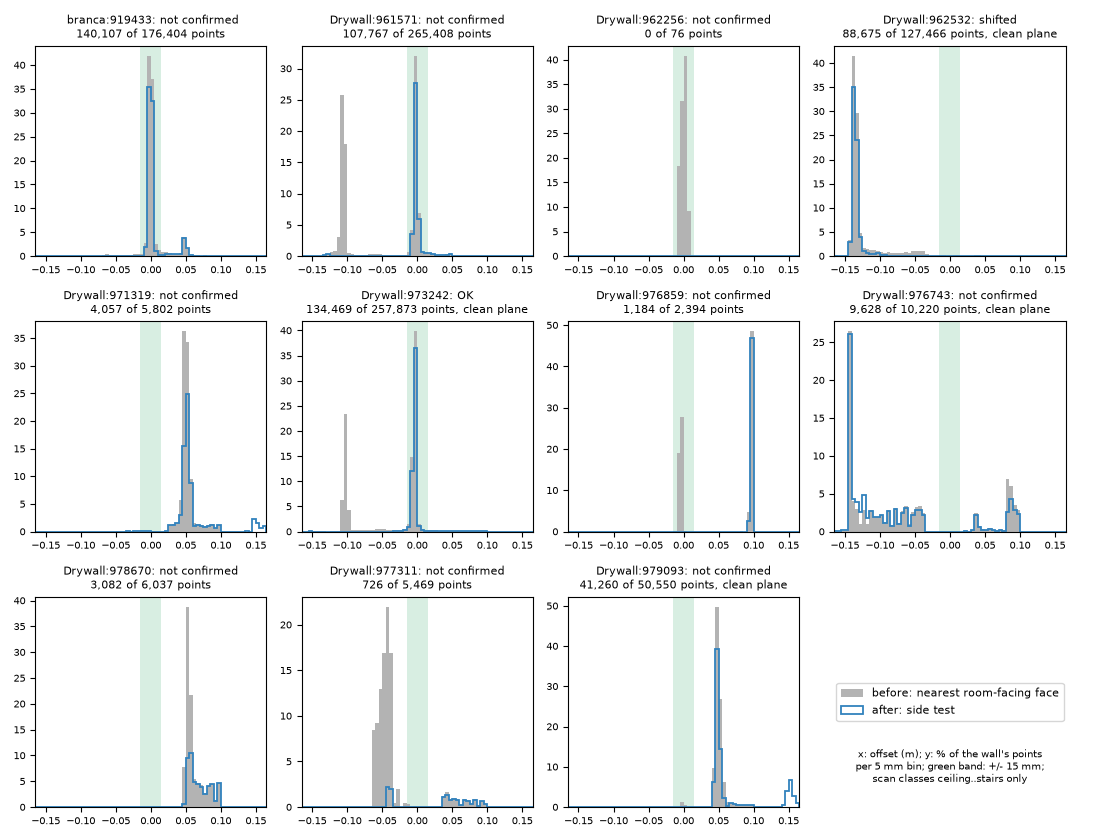

In [19]:
# Per-wall offset histograms (before: the nearest room-facing face; after: the side test, reference-side offsets), and the walls that are clean single planes.
# "Clean single plane" is defined without the verdict rule (no median offset, no share within TOL of the model): the scan class 'wall' points that the side test
# counts, between z `CLEAN_Z` and at least `EDGE` from every other element (so not at a junction with the ceiling, floor, a window, the door or another wall);
# the plane is the mode of their thickness coordinate (5 mm bins), refined to the median of the points within TOL of it; clean = at least MIN_POINTS such points and
# at least MIN_FRAC_OK of them within TOL of that plane. The plane's offset from the model's room-facing face is then a separate fact about the wall.
oracle_wall = SCAN_CLASS == CLASS_NAMES.index("wall")
plane_rows = {}
for i in walls:
    w = SIDE_TEST.walls[i]
    a, ref = w["axis"], w["ref"]
    idx = points_of[i][oracle_wall[points_of[i]]]
    d_other = SIDE_TEST.d_other[idx]  # from measure(): distance to the nearest other element
    plain = idx[(d_other > EDGE) & (P[idx, 2] > CLEAN_Z[0]) & (P[idx, 2] < CLEAN_Z[1])]
    row = dict(i=i, n_class=len(idx), n_plain=len(plain), clean=False)
    if len(plain) >= MIN_POINTS:
        u = P[plain, a]
        h, edges = np.histogram(u, np.arange(u.min(), u.max() + 0.005, 0.005))
        u0 = float(np.median(u[np.abs(u - (edges[np.argmax(h)] + 0.0025)) <= TOL]))
        near = np.abs(u - u0) <= TOL
        vv = elements[i].vertices[:, a]
        u_face = vv.max() if ref > 0 else vv.min()
        row.update(plane_mm=(u0 - u_face) * ref * 1000, inliers=float(near.mean()), rms_mm=float(np.sqrt(np.mean((u[near] - u0) ** 2))) * 1000,
                   within_tol_plain=float(np.mean(np.abs(signed[plain]) <= TOL)), clean=bool(near.mean() >= MIN_FRAC_OK))
    plane_rows[i] = row
print(f"{'wall':16s} {'wall-class pts':>14s} {'plain area':>10s} {'plane vs model face':>20s} {'in plane':>9s} {'rms':>7s} {'clean plane':>12s} | {'verdict (labels)':>16s} {'within tol, whole wall':>23s} {'within tol, plain area':>23s}")
for i in walls:
    r, v = plane_rows[i], rows_oracle[i]
    plane = f"{r['plane_mm']:17.0f} mm {r['inliers']:9.1%} {r['rms_mm']:5.1f} mm" if "plane_mm" in r else f"{'':20s} {'':>9s} {'':>7s}"
    plain = f"{r['within_tol_plain']:23.1%}" if "plane_mm" in r else f"{'':>23s}"
    print(f"{META[GUIDS[i]]['name'][-14:]:16s} {r['n_class']:14,d} {r['n_plain']:10,d} {plane} {'yes' if r['clean'] else 'no':>12s} | {v['verdict']:>16s} {v['share_within_tol']:23.1%} {plain}")

# Known answers on the real model: every clean single plane that is within TOL of the model is a wall that should be OK, and is (with labels)
cleans = [i for i in walls if plane_rows[i]["clean"]]
near_model = [i for i in cleans if abs(plane_rows[i]["plane_mm"]) <= TOL * 1000]
print(f"\nclean single planes: {', '.join(META[GUIDS[i]]['name'][-14:] for i in cleans)}; of them within {TOL * 1000:.0f} mm of the model's room-facing face: "
      f"{', '.join(META[GUIDS[i]]['name'][-14:] for i in near_model)}")
assert [META[GUIDS[i]]["name"][-14:] for i in near_model] == ["Drywall:973242"]
for i in near_model:
    r = rows_oracle[i]
    print(f"{META[GUIDS[i]]['name'][-14:]}: {r['share_within_tol']:.1%} of its {r['point_count']:,} counted points within tolerance (MIN_FRAC_OK {MIN_FRAC_OK:.0%}), "
          f"{r['points_at_junction']:,} points within {JUNCTION * 100:.0f} cm of another element left out, {r['points_other_side']:,} the back of the wall -> {r['verdict']}")
    assert r["verdict"] == "OK", f"{META[GUIDS[i]]['name']} is a clean plane within tolerance of the model and should be OK"

fig, axs = plt.subplots(3, 4, figsize=(11, 8.4))
bins = np.arange(-165, 166, 5) / 1000
for ax, i in zip(axs.ravel(), walls):
    sel = (geom_id == i) & band & is_element_class
    before, after = SIDE_TEST.fallback[sel], signed[sel]
    after = after[~np.isnan(after)]
    ax.axvspan(-TOL, TOL, color="#2ca25f", alpha=0.18, lw=0)
    ax.hist(np.clip(before, -0.164, 0.164), bins, weights=np.full(len(before), 100 / max(len(before), 1)), color="0.7", label="before: nearest room-facing face")
    ax.hist(np.clip(after, -0.164, 0.164), bins, weights=np.full(len(after), 100 / max(len(before), 1)), histtype="step", color="#3182bd", lw=1.3, label="after: side test")
    ax.set_title(f"{META[GUIDS[i]]['name'][-14:]}: {rows_oracle[i]['verdict']}\n{len(after):,} of {len(before):,} points" + (", clean plane" if plane_rows[i]["clean"] else ""), fontsize=8)
    ax.tick_params(labelsize=7)
    ax.set_xlim(-0.165, 0.165)
for ax in axs.ravel()[len(walls):]:
    ax.axis("off")
axs.ravel()[len(walls)].legend(*axs.ravel()[0].get_legend_handles_labels(), loc="center", fontsize=8)
axs.ravel()[len(walls)].text(0.5, 0.12, "x: offset (m); y: % of the wall's points\nper 5 mm bin; green band: +/- 15 mm;\nscan classes ceiling..stairs only", ha="center", fontsize=7, transform=axs.ravel()[len(walls)].transAxes)
plt.tight_layout()
fig.savefig(OUT / "wall_offsets.png", dpi=100)  # 1100 x 840 px
plt.close(fig)
display(Image(filename=str(OUT / "wall_offsets.png"), width=1100))

### The junction margin's judgement call and the false-OK check

`JUNCTION` = 10 cm is a judgement call. The table shows the verdict counts for 0 (no margin), 5, 10 and 15 cm, and which walls are OK or shifted at each value, with the share of the wall's counted points that the margin removed. Then, for every wall that is OK or shifted at some margin but not at 0, the numbers before and after, and whether it is a clean plane by the definition above. A wall that became OK only because the margin threw away its disagreeing points would show up here as not a clean plane. The last print answers the question about the points above z 2.75 m.

In [20]:
# The junction margin's one judgement call, JUNCTION (0: no margin): verdict counts without / with labels, the walls that are OK or shifted at each value, and, for every wall
# that is OK or shifted only because of the margin, how much of it the margin removed and whether it is a clean plane by the definition above (which does not use the margin).
JS = (0.0, 0.05, 0.10, 0.15)
tabs = {}
for J in JS:
    v = VIEW if J == JUNCTION else side_view(junction=None if J == 0 else J)
    tabs[J] = {"no_labels": verdict_table(np.ones(len(P), bool), view=v), "oracle_labels": verdict_table(is_element_class, view=v)}
tag = lambda r: r["name"].split(":")[-1][:4]
print(f"{'JUNCTION':>9s} {'without labels (OK / shifted / not confirmed)':>46s} {'with labels':>14s}   walls that are OK or shifted (share within 15 mm, share of the wall's points removed)")
for J in JS:
    a, b = counts(tabs[J]["no_labels"]), counts(tabs[J]["oracle_labels"])
    walls_txt = []
    for variant, short_ in (("no_labels", "no labels"), ("oracle_labels", "labels")):
        for i in walls:
            r, r0 = tabs[J][variant][i], tabs[0.0][variant][i]
            if r["verdict"] in ("OK", "shifted"):
                removed = 1 - r["point_count"] / max(r0["point_count"], 1)
                walls_txt.append(f"{short_}: {tag(r)} {r['verdict']} ({r['share_within_tol']:.1%}, {removed:.0%})")
    print(f"{J * 100:6.0f} cm {a['OK']:14d} / {a['shifted']:2d} / {a['not confirmed']:2d}{'':14s}   {b['OK']:3d} / {b['shifted']:2d} / {b['not confirmed']:2d}      " + "; ".join(walls_txt))
print("\nwalls whose verdict is OK or shifted at some JUNCTION > 0 but not at 0:")
for variant in ("no_labels", "oracle_labels"):
    for i in walls:
        r0 = tabs[0.0][variant][i]
        for J in JS[1:]:
            r = tabs[J][variant][i]
            if r["verdict"] in ("OK", "shifted") and r0["verdict"] != r["verdict"]:
                p = plane_rows[i]
                print(f"  {variant:13s} {tag(r)} at {J * 100:.0f} cm: {r0['verdict']} ({r0['share_within_tol']:.1%} within 15 mm, {r0['share_near_median']:.1%} near the median, {r0['point_count']:,} points) -> "
                      f"{r['verdict']} ({r['share_within_tol']:.1%}, {r['share_near_median']:.1%}, {r['point_count']:,} points; {1 - r['point_count'] / r0['point_count']:.0%} removed); "
                      + (f"clean plane {p['inliers']:.1%} within 15 mm of one plane at {p['plane_mm']:+.0f} mm from the model" if "plane_mm" in p else "no plane fit") + (", clean" if p["clean"] else ", NOT clean"))

# The points that spoiled the two big walls' shares were mostly above z 2.75 m (the ceiling junction; CEILING_PROBE_Z). Are they within the margin of a modelled element, or does the margin need a height clamp?
print(f"\nwith labels, the counted points outside 15 mm above z {CEILING_PROBE_Z} m (before the margin), distance to the nearest other element:")
for suffix in ("Drywall:961571", "Drywall:973242"):
    i = next(i for i in walls if META[GUIDS[i]]["name"].endswith(suffix))
    idx = np.flatnonzero((geom_id == i) & band & is_element_class & ~np.isnan(SIDE_TEST.signed_side))
    hi = idx[(np.abs(SIDE_TEST.signed_side[idx]) > TOL) & (P[idx, 2] > CEILING_PROBE_Z)]
    d = SIDE_TEST.d_other[hi] * 100
    print(f"  {suffix}: {len(hi):,} points of {(np.abs(SIDE_TEST.signed_side[idx]) > TOL).sum():,} outside tolerance; distance p10 / p50 / p90 / max {np.percentile(d, 10):.1f} / {np.percentile(d, 50):.1f} / {np.percentile(d, 90):.1f} / {d.max():.1f} cm; "
          f"{np.mean(d <= JUNCTION * 100):.1%} within {JUNCTION * 100:.0f} cm; scan classes " + ", ".join(f"{CLASS_NAMES[k]} {n:,}" for k, n in zip(*np.unique(SCAN_CLASS[hi], return_counts=True)) if n > 200))

# Which walls the margin takes below MIN_POINTS (with labels), that had enough points without it
print(f"\nwalls with fewer than MIN_POINTS = {MIN_POINTS:,} counted points at a margin but not without (with labels):")
for J in JS[1:]:
    gone_ = [f"{tag(tabs[J]['oracle_labels'][i])} ({tabs[0.0]['oracle_labels'][i]['point_count']:,} -> {tabs[J]['oracle_labels'][i]['point_count']:,})" for i in walls
             if tabs[0.0]["oracle_labels"][i]["point_count"] >= MIN_POINTS > tabs[J]["oracle_labels"][i]["point_count"]]
    print(f"  {J * 100:3.0f} cm: " + (", ".join(gone_) if gone_ else "none"))


 JUNCTION  without labels (OK / shifted / not confirmed)    with labels   walls that are OK or shifted (share within 15 mm, share of the wall's points removed)
     0 cm              5 /  0 / 30                   6 /  1 / 28      labels: 9625 shifted (0.9%, 0%)
     5 cm              5 /  0 / 30                   7 /  1 / 27      labels: 9625 shifted (0.0%, 9%); labels: 9732 OK (97.5%, 13%)
    10 cm              5 /  1 / 29                   7 /  1 / 27      no labels: 9625 shifted (0.5%, 26%); labels: 9625 shifted (0.0%, 22%); labels: 9732 OK (98.1%, 18%)
    15 cm              5 /  1 / 29                   7 /  1 / 27      no labels: 9625 shifted (0.4%, 41%); labels: 9625 shifted (0.0%, 35%); labels: 9732 OK (98.4%, 24%)

walls whose verdict is OK or shifted at some JUNCTION > 0 but not at 0:
  no_labels     9625 at 10 cm: not confirmed (1.6% within 15 mm, 73.1% near the median, 128,382 points) -> shifted (0.5%, 90.0%, 94,859 points; 26% removed); clean plane 99.5% within 15 mm of o

  Drywall:973242: 8,078 points of 13,606 outside tolerance; distance p10 / p50 / p90 / max 0.3 / 1.3 / 2.2 / 4.9 cm; 100.0% within 10 cm; scan classes ceiling 7,071, window 991

walls with fewer than MIN_POINTS = 2,000 counted points at a margin but not without (with labels):
    5 cm: none
   10 cm: 9773 (5,469 -> 726)
   15 cm: 9786 (6,037 -> 1,390), 9773 (5,469 -> 184)


### Why `Drywall:9732` is not OK without labels (a diagnosis; the decision is that criterion 1 closes on the OK with labels)

Without labels `Drywall:9732` is 81 % within 15 mm (not confirmed), with labels 98 % (OK). The cell below says what the 19 % is, whether point normals (the issue's own suggestion for a label-free filter) would remove it, and what the one rule that does reach 95 % does to the other walls.

**What the 19 % is.** 32,824 of its 174,061 counted points lie outside 15 mm: 53 % are clutter-class points (cabinet 5,684, all outside; board 10,594, 29 % outside; desk, divider, paper and alcohol dispensers), 39 % are unassigned points, 8 % are element-class points. 75 % are **in front** of the wall plane at +15 to +100 mm (cabinet fronts, boards, dispensers, objects against the wall), 25 % are behind it, mostly about 15 cm behind (a plane that the side test cannot place). By height: 22 % are below z 0.3 m, 40 % at z 1.3 to 2.0 m; the top 1 m of the wall is clean.

**Normals do not remove it.** Unoriented normals from a 4 cm neighbourhood (3 and 5 cm give the same within 0.3 points): the plane points have `|n . n_face|` of 1.00, but only 48 % of the outside points are non-parallel (`|cos| < 0.9`): the in-front clutter is mostly vertical surfaces parallel to the wall (cabinet fronts, boards; `|cos|` p50 0.92 for the in-front points). A filter that keeps `|cos| >= 0.7 ... 0.98` (46 to 11 degrees) gives 88.4 to 92.1 % within 15 mm and never reaches 95 %, while it throws away up to 17 % of the points. So the filter would not make the wall OK, and I did not add it.

**The slab rule, tried and rejected.** The only label-free rule that reaches 95 % treats the wall's *slab* as the volume between its dominant plane (the mode of the offsets, which must hold more than half the points) and one thickness behind it, and counts only points inside it (nothing in front of the plane, nothing behind the far face). It makes `Drywall:9732` OK without labels (99.0 %) and with labels (99.3 %), but it also makes **`Drywall:9615` OK (99.8 % without labels, 100 % with) and the east wall (`...pintura branca`) OK (99.4 % and 99.9 %)**, and `Drywall:9773` OK without labels (97.3 %, 726 plain points), where the independent clean-plane fit says `Drywall:9615` is not a clean plane (94.5 % in the plane) and neither is the east wall (90.1 %), and cannot fit `Drywall:9773` at all. Those OKs are made by discarding the points that disagree (the 12.8 cm plane behind `Drywall:9615`, the +50 mm bump and window parts of the east wall), which is the false-OK pattern the margin was checked against, so the rule is not used. The table prints every wall with and without the rule.

In [21]:
# Why is Drywall:9732 not OK without labels? Its counted points outside TOL, by scan class, offset and height; then the normal filter (the issue's own suggestion) and a slab rule.
i32 = next(i for i in walls if META[GUIDS[i]]["name"].endswith("Drywall:973242"))
a32, ref32 = SIDE_TEST.walls[i32]["axis"], SIDE_TEST.walls[i32]["ref"]
cnt = points_of[i32]  # all counted points of the wall, no labels
s32 = signed[cnt]
out32 = np.abs(s32) > TOL
cls = SCAN_CLASS[cnt]
clutter32 = ~is_element_class[cnt] & (cls != 0)
print(f"{META[GUIDS[i32]]['name'][-14:]}, no labels: {len(cnt):,} counted points, {out32.sum():,} outside {TOL * 1000:.0f} mm ({out32.mean():.1%})\n")


def composition(title, groups):
    print(f"{title:26s} {'points':>8s} {'of counted':>10s} {'of outside':>10s} {'own outside':>11s}")
    for label, m in groups:
        if m.sum():
            print(f"  {label:24s} {m.sum():8,d} {m.mean():10.1%} {(m & out32).sum() / out32.sum():10.1%} {out32[m].mean():11.1%}")


composition("scan class", [("element classes", is_element_class[cnt]), ("unassigned", cls == 0), ("clutter classes", clutter32)] +
            [(f"  {CLASS_NAMES[k]}", cls == k) for k in np.unique(cls[clutter32]) if (cls == k).sum() > 1500])
composition("offset (mm, + into the room)", [(f"{lo * 1000:+.0f} to {hi * 1000:+.0f}", (s32 > lo) & (s32 <= hi)) for lo, hi in ((-1, -0.1), (-0.1, -TOL), (-TOL, TOL), (TOL, 0.05), (0.05, 1))])
composition("height (m)", [(f"z {lo} to {hi}", (P[cnt, 2] >= lo) & (P[cnt, 2] < hi)) for lo, hi in ((0, 0.3), (0.3, 0.8), (0.8, 1.3), (1.3, 2.0), (2.0, 3.1))])

# Unoriented normals from the scan itself, on the slab of the crop around this wall only (the neighbours of the wall's points are inside it)
def wall_cos(radius):
    # |n . n_face| per counted point: the wall's faces have their normal along the thickness axis
    ids = np.flatnonzero(np.abs(P[:, a32] - np.median(P[cnt, a32])) <= BAND + 0.15 + radius)
    cloud = o3d.geometry.PointCloud(o3d.utility.Vector3dVector(P[ids].astype(np.float64)))
    cloud.estimate_normals(o3d.geometry.KDTreeSearchParamHybrid(radius=radius, max_nn=50))
    row_of = np.full(len(P), -1)
    row_of[ids] = np.arange(len(ids))
    return np.abs(np.asarray(cloud.normals)[row_of[cnt], a32]), len(ids)


cos32, n_slab = wall_cos(DIAG_NORMAL_RADIUS)
print(f"\nnormals from a {DIAG_NORMAL_RADIUS * 100:.0f} cm neighbourhood ({n_slab:,} crop points in the wall's slab): |n . n_face| of the points inside / outside {TOL * 1000:.0f} mm, and of the outside points by group")
for label, m in (("inside", ~out32), ("outside", out32), ("outside, clutter classes", out32 & clutter32), ("outside, unassigned", out32 & (cls == 0)), ("outside, element classes", out32 & is_element_class[cnt]),
                 ("outside, in front (+)", out32 & (s32 > 0)), ("outside, behind (-)", out32 & (s32 < 0))):
    print(f"  {label:26s} {m.sum():7,d} points, |cos| p10 / p50 / p90 {np.percentile(cos32[m], 10):.2f} / {np.percentile(cos32[m], 50):.2f} / {np.percentile(cos32[m], 90):.2f}; |cos| >= 0.9: {np.mean(cos32[m] >= 0.9):.0%}")
print(f"\nnormal filter (keep |cos| >= threshold), share within {TOL * 1000:.0f} mm and share of the points kept, by neighbourhood radius (MIN_FRAC_OK {MIN_FRAC_OK:.0%}):")
for radius in (0.03, DIAG_NORMAL_RADIUS, 0.05):
    cos_r = cos32 if radius == DIAG_NORMAL_RADIUS else wall_cos(radius)[0]
    print(f"  {radius * 100:.0f} cm: " + "   ".join(f"{np.degrees(np.arccos(th)):.0f} deg: {np.mean(~out32[cos_r >= th]):.1%} ({np.mean(cos_r >= th):.0%})" for th in (0.7, 0.8, 0.9, 0.95, 0.98)))

# The slab rule (tried, not used): a wall's slab is the volume between its dominant plane and one thickness behind it; points in front of the plane or behind the far face are not the wall.
SLAB_MAJORITY = 0.5  # (diagnostic only) the slab rule needs the dominant plane to hold more than this share of the points


def slab_keep(s, thickness):
    h, e = np.histogram(s, np.arange(-0.4, 0.4, 0.005))
    mode = e[np.argmax(h)] + 0.0025
    if np.mean(np.abs(s - mode) <= TOL) <= SLAB_MAJORITY:
        return np.ones(len(s), bool)
    return (s - mode <= TOL) & (s - mode >= -(thickness + TOL))


print(f"\nslab rule, per wall (base verdict -> verdict with the slab rule; flips marked; the independent clean-plane fit next to it):")
for variant, use in (("no labels", np.ones(len(P), bool)), ("with labels", is_element_class)):
    for i in walls:
        idx = points_of[i][use[points_of[i]]]
        if len(idx) < MIN_POINTS:
            continue
        thick = float(np.ptp(elements[i].vertices[:, SIDE_TEST.walls[i]["axis"]]))
        base_j = judge(signed[idx].astype(np.float64), area_in_box[i])
        slab_j = judge(signed[idx[slab_keep(signed[idx], thick)]].astype(np.float64), area_in_box[i])
        p = plane_rows[i]
        flip = "  <- FLIP" + (" TO OK" if slab_j["verdict"] == "OK" else "") if slab_j["verdict"] != base_j["verdict"] else ""
        print(f"  {variant:11s} {META[GUIDS[i]]['name'].split(':')[-1][:4]}: {base_j['verdict']:13s} {base_j['share_within_tol']:6.1%} -> {slab_j['verdict']:13s} {slab_j['share_within_tol']:6.1%} ({slab_j['point_count'] / len(idx):4.0%} kept); "
              + (f"independent fit: {'clean' if p['clean'] else 'NOT clean'} ({p['inliers']:.1%} in plane, {p['n_plain']:,} plain points)" if "plane_mm" in p else f"independent fit: {p['n_plain']:,} plain points, no fit") + flip)

Drywall:973242, no labels: 174,061 counted points, 32,824 outside 15 mm (18.9%)

scan class                   points of counted of outside own outside
  element classes           134,469      77.3%       7.9%        1.9%
  unassigned                 13,548       7.8%      39.2%       95.1%
  clutter classes            26,044      15.0%      52.8%       66.6%
    desk                      3,242       1.9%       9.2%       93.1%
    cabinet                   5,684       3.3%      17.3%      100.0%
    board                    10,594       6.1%       9.2%       28.6%
    paper dispenser           1,788       1.0%       4.2%       78.0%
    alcohol dispenser         1,969       1.1%       4.4%       74.0%
    divider                   2,500       1.4%       7.6%      100.0%
offset (mm, + into the room)   points of counted of outside own outside
  -1000 to -100               6,709       3.9%      20.4%      100.0%
  -100 to -15                 1,424       0.8%       4.3%      100.0%
  -15 t


normals from a 4 cm neighbourhood (562,445 crop points in the wall's slab): |n . n_face| of the points inside / outside 15 mm, and of the outside points by group
  inside                     141,237 points, |cos| p10 / p50 / p90 1.00 / 1.00 / 1.00; |cos| >= 0.9: 97%
  outside                     32,824 points, |cos| p10 / p50 / p90 0.08 / 0.86 / 1.00; |cos| >= 0.9: 48%
  outside, clutter classes    17,347 points, |cos| p10 / p50 / p90 0.11 / 0.92 / 1.00; |cos| >= 0.9: 53%
  outside, unassigned         12,883 points, |cos| p10 / p50 / p90 0.09 / 0.85 / 1.00; |cos| >= 0.9: 48%
  outside, element classes     2,594 points, |cos| p10 / p50 / p90 0.01 / 0.21 / 1.00; |cos| >= 0.9: 17%
  outside, in front (+)       24,691 points, |cos| p10 / p50 / p90 0.11 / 0.92 / 1.00; |cos| >= 0.9: 53%
  outside, behind (-)          8,133 points, |cos| p10 / p50 / p90 0.05 / 0.33 / 1.00; |cos| >= 0.9: 32%

normal filter (keep |cos| >= threshold), share within 15 mm and share of the points kept, by neighbou

  3 cm: 46 deg: 88.3% (91%)   37 deg: 88.9% (90%)   26 deg: 89.6% (88%)   18 deg: 90.6% (86%)   11 deg: 91.9% (83%)
  4 cm: 46 deg: 88.4% (91%)   37 deg: 89.0% (89%)   26 deg: 89.7% (88%)   18 deg: 90.9% (86%)   11 deg: 92.1% (83%)


  5 cm: 46 deg: 88.4% (90%)   37 deg: 89.0% (89%)   26 deg: 89.8% (88%)   18 deg: 91.0% (86%)   11 deg: 92.1% (83%)

slab rule, per wall (base verdict -> verdict with the slab rule; flips marked; the independent clean-plane fit next to it):
  no labels   9194: not confirmed  85.9% -> OK             99.4% ( 86% kept); independent fit: NOT clean (90.1% in plane, 139,543 plain points)  <- FLIP TO OK
  no labels   9615: not confirmed  68.0% -> OK             99.8% ( 68% kept); independent fit: NOT clean (94.5% in plane, 107,134 plain points)  <- FLIP TO OK
  no labels   9622: not confirmed  19.7% -> not confirmed  19.7% (100% kept); independent fit: 0 plain points, no fit
  no labels   9625: shifted         0.5% -> shifted         0.0% ( 90% kept); independent fit: clean (99.5% in plane, 86,052 plain points)
  no labels   9713: not confirmed  11.3% -> not confirmed  11.3% (100% kept); independent fit: NOT clean (94.8% in plane, 3,734 plain points)
  no labels   9732: not confirmed  81.1% -

## 5. Outputs

`verdicts_oracle_labels.csv` and `verdicts_no_labels.csv` hold one row per element, starting with `global_id, ifc_class, verdict, point_count, median_signed_offset_mm`, then `name, inside_box, area_in_box_frac, share_within_tol, share_near_median, spread_mm, reason` (`share_near_median` is the share of points within `TOL` of the element's median offset, the one-cluster test for shifted; `spread_mm` is informational), and, new with the side test, `points_other_side` (walls: points seen from the neighbouring room and left out), `ambiguous_share` (walls: share of the counted points whose side the scan could not tell), `reference_side` (walls: the outward normal the offsets are expressed along; **for a wall with two room-facing sides the offset is positive along this normal, not towards the room at the nearest face**) and `room_facing_sides` (1 or 2) and `points_at_junction` (walls: points left out for lying within `JUNCTION` of another element; 0 for other classes); the first four of these five are empty for other classes. `point_count` is the number of counted points (neither the back of a wall nor the points at a junction are counted). `frame.json` has the recorded and refined transforms, the ICP correction and the RANSAC check. `wall_offsets.png` is the per-wall histogram figure. The top-down figure is a plan: scan points coloured by the verdict of the element they were assigned to (grey: not assigned to an element, left out by the labels, or the back of a wall), the model cut as black lines, the room box as a red dashed outline. A plan of the whole room would be hidden by the ceiling and the floor, so three height slabs are shown: floor level, chest height (walls, door, column) and window / ceiling height.

In [22]:
FIELDS = ["global_id", "ifc_class", "verdict", "point_count", "median_signed_offset_mm", "name", "inside_box", "area_in_box_frac",
          "share_within_tol", "share_near_median", "spread_mm", "reason", "points_other_side", "ambiguous_share", "reference_side", "room_facing_sides", "points_at_junction"]
for variant, rows in (("oracle_labels", rows_oracle), ("no_labels", rows_no_labels)):
    with open(OUT / f"verdicts_{variant}.csv", "w", newline="") as f:
        w = csv.DictWriter(f, FIELDS)
        w.writeheader()
        for r in rows:
            w.writerow({k: ("" if isinstance(v, float) and np.isnan(v) else round(v, 4) if isinstance(v, float) else v) for k, v in r.items()})

RESULT = {
    "note": "scan_to_model 4x4 matrices: apply to scan points to get the model frame. Recorded is from notebook 01; refined is ICP from it on all room points (no labels), used by both verdict runs.",
    "recorded_scan_to_model_4x4": T_REC.tolist(),
    "refined_scan_to_model_4x4": T_REFINED.tolist(),
    "refined_oracle_labels_scan_to_model_4x4": T_REFINED_ORACLE.tolist(),
    "icp_correction": {"rotation_deg": float(corr_rot), "room_centroid_mm": float(corr_trans * 1000), "room_centroid_model_frame": c_room.tolist(),
                       "sanity_bounds": {"rotation_deg": SANITY_ROT_DEG, "translation_m": SANITY_TRANS_M}},
    "oracle_refinement_vs_no_labels": {"rotation_deg": float(or_rot), "room_centroid_mm": float(or_trans * 1000)},
    "ransac_check_vs_recorded": [{k: v for k, v in r.items() if k != "T"} for r in ransac_runs],
    "registration_residual_m": {"recorded": dist_stats(d_recorded), "refined": dist_stats(d_refined)},
}
(OUT / "frame.json").write_text(json.dumps(RESULT, indent=1))
print("wrote", *sorted(p.name for p in OUT.iterdir()))

wrote frame.json verdicts_no_labels.csv verdicts_oracle_labels.csv verdicts_top_down.png wall_offsets.png


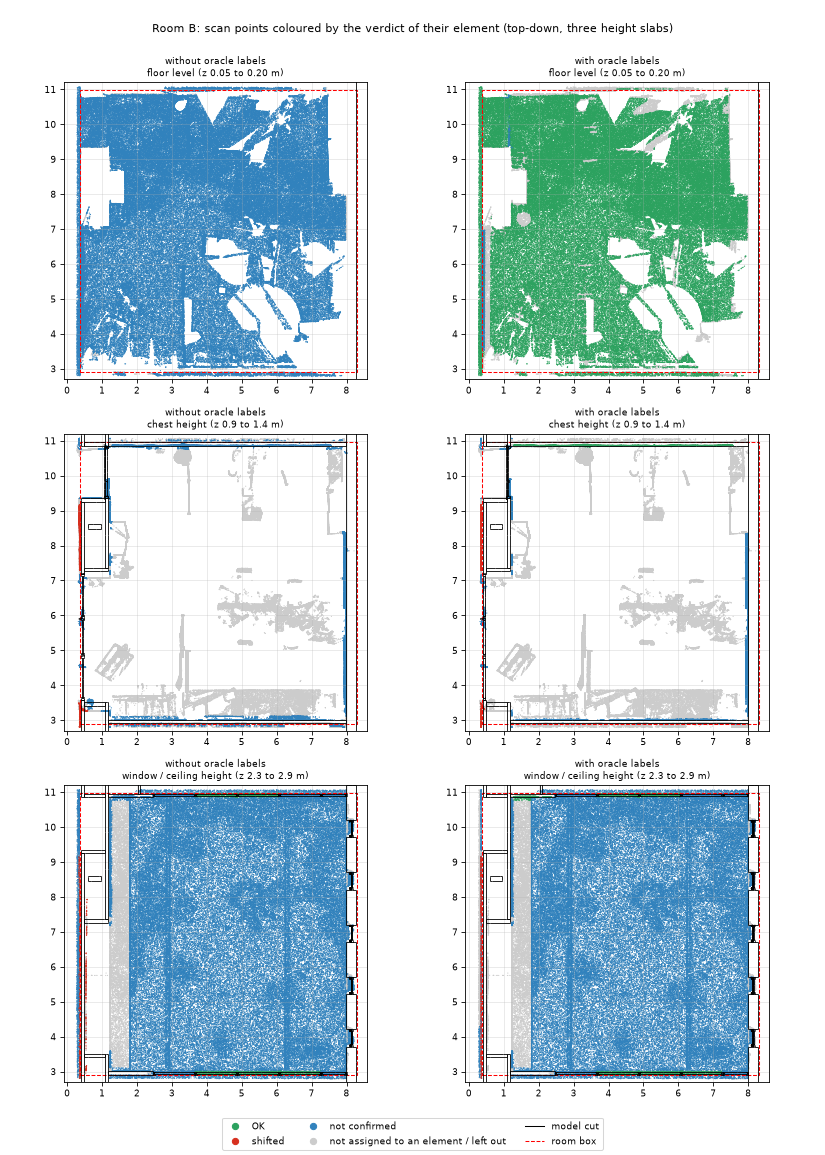

peak RSS 1.05 GB, notebook run 229 s


In [23]:
VERDICT_COLOUR = {"OK": "#2ca25f", "shifted": "#d7301f", "not confirmed": "#3182bd"}
GREY = np.array([0.80, 0.80, 0.80])
rgb = lambda h: np.array([int(h[k:k + 2], 16) / 255 for k in (1, 3, 5)])
SLABS = [("floor level (z 0.05 to 0.20 m)", 0.05, 0.20, 0.05), ("chest height (z 0.9 to 1.4 m)", 0.9, 1.4, 1.15),
         ("window / ceiling height (z 2.3 to 2.9 m)", 2.3, 2.9, 2.5)]  # name, z range, height of the model cut


def section(elements, axis, value):
    # Line segments where the plane axis == value cuts the elements' triangles: (n, 2, 2), two end points in the other two axes.
    keep = [i for i in range(3) if i != axis]
    out = []
    for e in elements:
        v = e.vertices
        if v[:, axis].min() >= value or v[:, axis].max() <= value:
            continue
        tri = v[e.faces]
        s = tri[:, :, axis] - value
        S = np.full((len(tri), 2, 2), np.nan)
        count = np.zeros(len(tri), int)
        for i, j in ((0, 1), (1, 2), (2, 0)):
            idx = np.where(s[:, i] * s[:, j] < 0)[0]
            t = s[idx, i] / (s[idx, i] - s[idx, j])
            S[idx, count[idx]] = tri[idx, i][:, keep] + t[:, None] * (tri[idx, j][:, keep] - tri[idx, i][:, keep])
            count[idx] += 1
        out.append(S[count == 2])
    return np.concatenate(out) if out else np.zeros((0, 2, 2))


rs = np.random.default_rng(SEED)
fig, axs = plt.subplots(3, 2, figsize=(11, 15.4))
for row, (title, z0, z1, z_cut) in enumerate(SLABS):
    slab = np.flatnonzero((P[:, 2] >= z0) & (P[:, 2] <= z1))
    pick = np.sort(rs.choice(slab, min(150_000, len(slab)), replace=False))
    cuts = section(elements, 2, z_cut)
    for col, (rows, use, label) in enumerate(((rows_no_labels, np.ones(len(P), bool), "without oracle labels"),
                                              (rows_oracle, is_element_class, "with oracle labels"))):
        element_colour = np.array([rgb(VERDICT_COLOUR[r["verdict"]]) for r in rows])
        coloured = in_band[pick] & use[pick]
        colour = np.where(coloured[:, None], element_colour[geom_id[pick]], GREY)
        order = np.argsort(coloured, kind="stable")  # grey first, verdict colours on top
        ax = axs[row, col]
        ax.scatter(P[pick[order], 0], P[pick[order], 1], s=1.2, c=colour[order], linewidths=0, rasterized=True)
        ax.add_collection(LineCollection(cuts, colors="k", linewidths=0.8))
        ax.add_patch(plt.Rectangle(box_lo[:2], *(box_hi - box_lo)[:2], fill=False, ec="r", ls="--", lw=1))
        ax.set_xlim(-0.1, 8.6); ax.set_ylim(2.7, 11.2); ax.set_aspect("equal"); ax.grid(alpha=0.3)
        ax.set_title(f"{label}\n{title}", fontsize=9)
fig.legend(handles=[plt.Line2D([], [], marker="o", ls="", ms=6, color=c, label=v) for v, c in VERDICT_COLOUR.items()] +
           [plt.Line2D([], [], marker="o", ls="", ms=6, color=GREY, label="not assigned to an element / left out"),
            plt.Line2D([], [], color="k", lw=1, label="model cut"), plt.Line2D([], [], color="r", ls="--", lw=1, label="room box")],
           loc="lower center", ncol=3, fontsize=9)
fig.suptitle("Room B: scan points coloured by the verdict of their element (top-down, three height slabs)")
plt.tight_layout(rect=(0, 0.04, 1, 0.98))
fig.savefig(OUT / "verdicts_top_down.png", dpi=75)  # 825 x 1155 px: under 1200 in both dimensions, and a smaller notebook
plt.close(fig)
display(Image(filename=str(OUT / "verdicts_top_down.png"), width=825))
print(f"peak RSS {peak_rss_gb():.2f} GB, notebook run {time.time() - T0:.0f} s")


## Answer

Room B of the CRAS lab, 35 elements, USIBD LOA30 (15 mm at 2 sigma, so 95 % of an element's points within 15 mm for OK), one transform (refined from 01's, no labels) for both runs. Issue #17 changed how walls are measured: the **wall side test** and the **junction margin** (section 3); everything else is as before.

**Verdicts.** Without oracle labels: **5 OK, 1 shifted, 29 not confirmed**. With oracle labels: **7 OK, 1 shifted, 27 not confirmed**. With the side test but no junction margin the counts were 5 / 0 / 30 and 6 / 1 / 28; with the room-facing rule alone 5 / 1 / 29 and 6 / 2 / 27 (and 5 / 3 / 27 and 7 / 5 / 23 with the nearest-face offsets before that). Missing and not visible do not occur: 01 recovered no scanner positions (1 of 21, outside the box), so that branch is not implemented. OK needs 95 % of the points within 15 mm (`MIN_FRAC_OK`, LOA30's confidence level, unchanged); shifted needs `|median| > 15 mm` and `MIN_FRAC_CLUSTER` = 80 % of the points within 15 mm of the median, a judgement call that is not from the standard. The sliver rule moves 2 coverings from OK to not confirmed (under 1 % of their surface in the box, OK on a 10 cm strip).

- **OK (5 without labels):** five windows, with median offsets within 0.3 mm and 95 to 98 % of their points inside 15 mm. With labels two more: the floor slab (98 % inside 15 mm with labels, 88 % without) and **`Drywall:9732`, the first wall that is OK**: 98.1 % of its 134,469 counted points within 15 mm, median -3.9 mm. Of its band points 93,527 are the back of the wall (seen from the neighbouring room) and 29,877 lie within 10 cm of another element and are left out. Without labels it is 81 % (clutter and unassigned points).
- **Shifted (1 in each run):** the **thin west wall** `Drywall:9625` at **-135 mm** (with labels -135.3 mm, 96 % of its 88,675 counted points within 15 mm of the median; without labels -135.1 mm, 90 % of 94,859). Its scan surface (median x 0.356 m) is 13.4 cm behind the modelled room-facing face at x 0.49 m, and 3.4 cm behind even the modelled outer face. Without labels it is new: before the margin it was 73 % near the median and not confirmed, the margin removed 26 % of its points (junctions with the other elements) and left 90 %. It is a clean plane at -136 mm by the independent definition, so shifted is right and this is not a false flag. `Drywall:9790` was shifted at +49 mm before the side test and is **not confirmed** now (70 % near the median without labels, 76 % with), see below.
- **Not confirmed (29 without labels, 27 with):** without labels, 21 are "inconsistent offsets" (10 windows, 8 walls, the door, the floor slab and the ceiling covering), 5 are "mostly outside the room box" (four coverings and one wall with 0 to 9 % of their surface in the box) and 3 are "too few points" (the column, 78 points within 10 cm; a window with 1,965 points, 35 short of `MIN_POINTS`; and `Drywall:9768`, 1,614 points left after 1,495 are the back of the wall). With labels: 17 inconsistent (10 windows, 5 walls, the door, the covering), 5 outside the box, 5 too few points (the column, none with labels; the same window; `Drywall:9622` with 0 after the margin, `Drywall:9768` 1,184 and `Drywall:9773` with 726: the margin removed 4,743 of its 5,469 points, a partition that is mostly junction). Many of the "inconsistent offsets" are near misses of the 95 % line, not scattered: the ceiling covering 92 %, the slab 88 % (without labels), windows at 87 to 93 %, `Drywall:9615` 94.4 % with labels. At 80 % the OK count is 15 without labels and 15 with.
- **With vs without labels:** 2 elements change, both from not confirmed: the floor slab (696,945 points without labels, 594,879 with) and `Drywall:9732` (174,061 and 134,469 points, 81 % and 98 %) become OK. The only difference between the runs is the points, so the cause is clutter and unassigned points within 10 cm of these elements. The other 33 verdicts agree.

**The wall side test, as measured.** `Drywall:9615` (south wall) and `Drywall:9732` (north wall) are the walls the issue is about. Of their 328,138 and 360,985 band points, **45 % and 42 % are the back of the wall (seen from the neighbouring room) and are left out**; 59 % and 68 % were decided by their own free space, 28 % and 23 % by the plane vote, 13 % and 9 % stayed ambiguous (nearest room-facing face). The check against the model's two faces (section 3) is clean: with the vote, no far-face point is counted and every room-face point is, on both walls; with the free-space test alone (the design as specified) 23 to 37 % of the far face is still counted and 13 to 21 % of what the wall is judged on is the neighbour's surface, because 88 to 92 % of those points have no partner face behind them to see. The other 9 walls are ambiguous for 54 to 97 % of their band points (their other face is not scanned, or both sides are occupied), so for them the nearest room-facing face still decides, folding included. **`VOTE_SHARE` is a judgement call and the result depends on it** (table in section 4, with the margin): with 0.3 `Drywall:9615` also reaches 95 % (8 OK with labels), with 0.5 (used) it has 3 % ambiguous points and 94 %, with 0.7 it falls back to 47 % ambiguous and 65 %, with 0.9 or no vote both big walls are 30 to 47 % ambiguous and `Drywall:9732` is not OK (93 %).

**The junction margin and the clean walls (acceptance criterion 1, met with oracle labels).** Four walls are clean single planes by the definition that does not use the verdict rule (section 4): the west wall `Drywall:9625` (99.5 %, plane at **-136 mm** from the model's room-facing face), `Drywall:9767` (99.7 %, -141 mm), `Drywall:9790` (98.2 %, +49 mm) and `Drywall:9732` (98.9 %, **-4 mm**). Only `Drywall:9732` is a clean plane within tolerance of the model, and **it is OK** (with labels; asserted in the notebook). The other three are displaced walls, so shifted is their right verdict: the west wall gets it, `Drywall:9767` and `Drywall:9790` are mostly ambiguous (91 % and 80 to 81 % of their counted points) and are not shifted (below). `Drywall:9615` is not a clean plane by the definition (94.5 % of its plain-area points within 15 mm of a plane at -2 mm), and the east wall (`...pintura branca`, 30 cm) is at 90.1 % (a bump at +50 mm, visible in its histogram). **The clean-plane definition uses the same 10 cm edge exclusion as the margin** (`EDGE` = `JUNCTION`), so it cannot detect a false OK that the margin causes; that is what known answer i guards (a wall displaced by 3 cm, meeting a ceiling and another wall, reads shifted at +30 mm with the margin, never OK). **Without labels the wall stays 81 % (not confirmed), and criterion 1 closes on the OK with labels**: this is the decision of the project owner after the diagnosis in section 4. The 19 % is clutter in front of the wall (cabinet fronts, boards, dispensers, unassigned objects: 53 % clutter-class, 39 % unassigned, 8 % element-class; 75 % of it 15 to 100 mm in front of the plane), about half of it parallel to the wall, so a normal filter (11 to 46 degrees, 3 to 5 cm neighbourhoods) reaches at most 92.1 % within 15 mm; the only label-free rule that reaches 95 % (a slab rule: only points between the dominant plane and one thickness behind it) also makes `Drywall:9615` and the east wall OK by discarding points that disagree, which the independent clean-plane fit does not support (94.5 % and 90.1 % in the plane), so it is not used. **The gap between the two runs on this wall, 81 % against 98 %, is the measured value of segmentation for a wall in this room.** **Why the margin and not a height clamp:** the counted points above z 2.75 m that kept `Drywall:9615` and `Drywall:9732` below 95 % are 4,509 and 8,078 points (ceiling-class and window-class), 0.3 to 4.9 cm from a modelled element, all within the 10 cm margin. **Sensitivity (section 4):** `JUNCTION` 0 / 5 / 10 / 15 cm give 5 / 0 / 30, 5 / 0 / 30, 5 / 1 / 29, 5 / 1 / 29 without labels and 6 / 1 / 28, 7 / 1 / 27, 7 / 1 / 27, 7 / 1 / 27 with labels. Two walls change verdict with the margin, and neither is a false verdict: `Drywall:9732` is OK at 5, 10 and 15 cm (97.5, 98.1 and 98.4 % within 15 mm; 13, 18 and 24 % of its points removed) and is a clean plane (98.9 %) at -4 mm; the west wall is shifted without labels at 10 and 15 cm (90 % and 97 % near the median; 26 % and 41 % of its points removed) and is a clean plane at -136 mm. No other wall becomes OK or shifted at any margin, and `MIN_FRAC_OK` stays 0.95. Large margins remove walls instead of fixing them (with labels, from the sensitivity cell: at 10 cm `Drywall:9773` falls below `MIN_POINTS`, 5,469 -> 726 points; at 15 cm also `Drywall:9786`, 6,037 -> 1,390, and `Drywall:9773` 5,469 -> 184). The margin removes real disagreement as well (a window reveal that is truly off the plane, a bulge near the ceiling): a wall's verdict is a statement about its plain area, and `points_at_junction` says how much was left out (9 to 10 % of the two big walls' band points, 23 % of the west wall's, 45 to 52 % of the two small partitions').

**What the side test and the margin do not fix.** (1) `Drywall:9790` (`979093`, a partition at x 1.08 to 1.18 m) went from shifted to not confirmed: 80 % of its points are ambiguous and fall back to the nearest face, the +x face, at +50 mm; the 10,280 points that decide themselves are measured against the -x face and land at +152 mm (p50; the ambiguous 49,524 at +49 mm). It has a clean plane at x 1.23 m, 49 mm from the +x face and 149 mm from the -x face; if the real wall stands at x 1.23 to 1.33 m the +49 mm was a fold, as the issue says for partitions, but I did not check. (2) `Drywall:9768` (`976859`) loses its room-face points because a surface 95 mm in front of it looks like the wall's other face: both of its clusters are door-class, 1,422 points at 0 (all left out as the back of the wall) and 1,464 at +95 mm (1 left out); the counts are in the evidence cell. (3) The partitions `Drywall:9786` and `Drywall:9773` are ambiguous for 76 to 99 % of their counted points (occupied on both sides within 20 cm; I did not check by what), so a moved partition there still folds; 03b's 10 cm move is `Drywall:9786`.

**Sign convention.** For a wall with one room-facing side nothing changed (positive towards the room). For a wall with two room-facing sides (the partitions: `Drywall:9622`, `9713`, `9786`, `9773`, `9790`) the offset is positive along the **reference side's** normal (the side with more points; the CSV column `reference_side`), not towards the room at the nearest face. Notebook 04a says "positive into the room (03a's convention)": that sentence is now only true for walls with one room-facing side.

**Frame.** The coarse check does not confirm the recorded transform and does not refute it. RANSAC is the coarse step of 02's method; run here, in the as-delivered frame, on this room it failed: FPFH + RANSAC lands within 2 degrees and 5 cm of the recorded transform on **0 of 5** seeds (rotations of 79 to 172 degrees, room centroid 0.3 to 1.2 m off), which is what a cluttered, nearly box-shaped room does to it (02 saw the same on UVigo). So RANSAC did not provide the starting point here: the recorded transform from 01 (itself a coarse FFT step plus ICP) is what ICP refines. ICP started from it stays where it is: the correction is **0.11 degrees and 6.8 mm** at the room centroid (sanity bounds 0.5 degrees and 5 cm), and refining on oracle-label points only differs from the no-label refinement by 0.009 degrees and 0.3 mm. Registration residual after refinement for the element-class points in the box: median 5.4 mm, p90 40 mm, p99 247 mm (floor: p99 12 mm).

**01's p99 tail.** 5.0 % of the element-class points in the box (114,247) lie more than 10 cm from every element, which is what makes the in-room p99 247 mm (wall class alone: p99 371 mm; ceiling 247 mm, door 124 mm, window 116 mm, floor 12 mm). They sit in four places, each a real surface the model lacks or puts elsewhere: ceiling-class points at z 2.55 to 2.66 m along x 1.3 to 1.8 m (10 % of the ceiling class, median 0.24 m from the nearest element, which is a covering for 87 % of them); wall-class points at x about 1.23 m, y 3.8 to 7.2 m, median z 2.36 m, where the model's 10 cm wall at x 1.08 to 1.18 m has a gap (y 3.51 to 7.36 m); door-class points in a line at y 10.75 m, 11 cm from the nearest wall face (a wall for 99 % of them), which the one modelled door (at x 1.0 to 1.2 m) does not explain; and window-class points at x about 7.97 m, z 2.5 to 2.7 m, 13 cm in front of the glazing (a blind box or reveal, probably). So the residual tail is unmodelled or differently modelled geometry, not a registration failure (the median is 5.4 mm and the floor's p99 is 12 mm); I did not check the IFC or the scan further to say which of the two it is at each place. 01's 0.48 m (p99 after its ICP: 0.481 m) was measured differently: on 200,000 wall-class scan points sampled over the whole lab, against model walls and columns only (not doors, windows or coverings). So this room shows the same kind of cause, not that exact number.

**Triangle winding.** All 35 elements are outward-facing: walls, slab, column and coverings are closed solids (outward share 1.00), windows and doors are unions of overlapping solids (outward share 0.67 to 0.90, inward at most 0.23), so no element was flipped.

**Partly-inside elements.** 11 of the 35 cross a box face, and their verdicts cover only the part the cropped scan reaches: without labels the west wall is shifted and 10 are not confirmed (5 by the sliver rule); with labels the floor slab is OK, the west wall is shifted and 9 are not confirmed (5 by the sliver rule).

**Decision on the room box (acceptance criterion 3): keep the padded box (box plus `PAD` = 10 cm) for phase 0.5.** Strict box (no padding) against padded, with the side test and the margin: without labels 5 / 0 / 30 and 5 / 1 / 29, one element changes, the west wall (not confirmed on 7,768 points strict, shifted at -135.1 mm on 94,859 padded). With labels 8 / 0 / 27 against 7 / 1 / 27, two change: the west wall (1,772 points strict, 88,675 padded; 86,903 of those lie in the padding) and **`Drywall:9615`**, OK strict (96 % of 106,432 points) and not confirmed padded (94.4 % of 107,767). The 1,335 points that the padding adds to `Drywall:9615` are all on one plane: offsets p5 / p50 / p95 -134 / -128 / -125 mm, y 2.875 to 2.883 m, i.e. 12.8 cm behind the wall in the padding of the box whose south face is at y 2.90 m; the model has nothing there and the side test cannot place it (no partner face). The reasons for keeping the padding: (1) the west wall needs it (the box's west face is 1 cm outside the model wall and the scan surface is 13 cm behind it, so 98 % of its counted points are outside the box); (2) `Drywall:9615` is at the OK line either way (96 % strict, 94.4 % padded), its strict OK rests on the box edge cutting that plane off, and the padded, not-confirmed reading is the conservative one; (3) `Drywall:9732`, the one wall that is OK, is OK in both crops (98 %), and the old `Drywall:9773` flip is gone (not confirmed in both crops). So the walls are robust to the crop except where a verdict is already at the line.

**Follow-up, not done here: per-element patches.** The points within `BAND` of each element, whatever the box, which is what the padding approximates. They would take the crop out of the question (`Drywall:9615` and the west wall would be judged on the same points in every run). It changes 01's contract (the box stays for the room, the patches serve the verdict), so it is a separate issue. **Options not tried, and what they would buy:** a box redrawn on wall centre lines (01 writes `01_cras_slice.json`, which is not hand-edited): it would only move where the crop cuts the walls' thickness and keep a crop-dependent verdict, so it buys little over the padding; another room whose boundary walls are not on box faces (the issue's third option): it would test the side test on walls seen from one side and sidestep the padding question, but it is a different slice (new box, new elements, new 03b choices) and leaves room B's walls unexplained, so it fits the 05 validation better than this fix.

**Judgement calls.** `MIN_POINTS` 200 gives 5 / 2 / 28 without labels and 7 / 2 / 26 with (`Drywall:9768` and the west wall become shifted); 2,000 (used) gives 5 / 1 / 29 and 7 / 1 / 27; 20,000 would leave 0 OK without labels (0 / 1 / 34; 2 / 1 / 32 with labels). `MIN_FRAC_OK` carries the OK count: 0.95 (LOA30's confidence level) gives 5 / 1 / 29 without labels and 7 / 1 / 27 with; 0.8 (00's) gives 15 / 1 / 19 and 15 / 1 / 19. `MIN_FRAC_CLUSTER` carries the shifted count and is not from the standard: 0.95 gives 0 shifted without labels and 1 with (5 / 0 / 30 and 7 / 1 / 27), 0.8 gives 1 and 1, 0.7 gives 1 and 3, 0.6 gives 3 and 3. The synthetic 55 / 45 bimodal case is rejected at 0.8 but would pass at 0.55, so the value should not go much lower. `MIN_AREA_IN_BOX` (10 %) moves 2 elements, both OK on a 10 cm strip. `PROBE` (5 cm) only decides which faces of a wall are room-facing; I did not vary it. The side test adds `SIDE_NEAR` / `SIDE_FAR` (3 to 20 cm) and `OCC_VOXEL` (2 cm), neither varied, `VOTE_SHARE` (half; table in section 4), `JUNCTION` (10 cm; sensitivity above) and `EDGE` (10 cm, only in the clean-plane definition).
